# Trabalho final: Modelos de recomendação e análise de espaços latentes

**Disciplina:** *Aprendizado não-supervisionado* - *MC847*\
**Instituição:** *Universidade Estadual de Campinas*\
**Professor(a):** *Marcos Medeiros Raimundo*\
**Semestre:** *2s2026*

| Nome | RA |
|---|---|
| *Sara Beatriz da Silva Oliveira* | *231288* |
| *Integrante 2* | *RA 2* |

Preencha a tabela acima com os nomes e RAs dos integrantes da equipe (2 ou 3 alunos, impreterivelmente).

## Introdução

Em sistemas de recomendação, a principal tarefa é aprender a preferência de um usuário a partir de um histórico parcial de interações.
Isso pode ser visto como um problema de *completar informação*: dado o histórico parcial de um usuário, quais itens provavelmente faltam?
Neste trabalho vocês vão prever notas não observadas com modelos que fazem suposições diferentes sobre essa estrutura e, depois, investigar o que o espaço aprendido contém e quais suposições o produziram.

O trabalho é dividido em três etapas, sendo as duas primeiras comuns a todos os grupos e a terceira a ser definida por cada grupo.
A primeira etapa consiste em definir uma baseline que será usada como referência para as demais etapas.
A segunda consiste em realizar e analisar experimentos para entender como diferentes suposições sobre a estrutura latente dos dados afetam o desempenho do modelo.
A última etapa é a contribuição de cada grupo para o problema, que pode ser uma proposta de melhoria do modelo ou uma análise mais profunda de algum aspecto do problema.

As duas primeiras etapas têm códigos de referência, que podem ser usados como base para a implementação dos modelos.
Vocês podem usar bibliotecas externas com implementações de modelos, mas devem deixar claro quais bibliotecas foram usadas e como elas foram usadas.
Por exemplo, vocês podem reescrever o modelo de fatoração de matrizes em PyTorch ou Jax para melhorar a performance, desde que justifiquem a escolha e expliquem como a implementação foi mantida fiel ao modelo original.

## Dataset

Utilizaremos o conjunto de dados MovieLens 100K [(Harper e Konstan, 2015)](https://www.scirp.org/reference/referencespapers?referenceid=3586299): 100 mil notas inteiras de 1 a 5, dadas por 943 usuários a 1.682 filmes, com pelo menos 20 notas por usuário.
A matriz tem densidade de cerca de 6%, cada usuário tem idade (em anos), gênero e ocupação (21 categorias) e cada filme tem título, ano e 19 indicadores de gênero, e um filme pode ter vários gêneros.

Devido à natureza do problema, a ausência de notas não pode ser tratada como aleatória: Os motivos pelos quais um usuário não avaliou um item podem ser variados, incluindo falta de interesse, falta de exposição ao item ou simplesmente esquecimento.
Isso significa que os dados de treinamento são enviesados e não representam a distribuição real de preferências dos usuários.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from numpy.typing import NDArray

sns.set_theme(style="whitegrid")

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOVIELENS_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
DATA_DIR = "./data/"

def set_seed(seed: int) -> None:
    """Set the random seed for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [2]:
from pandas.core.frame import DataFrame

GENRES = [
    "unknown", "Action", "Adventure", "Animation", "Children's", "Comedy",
    "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"
]


def load_movielens() -> tuple[DataFrame, DataFrame, DataFrame]:
    """Download and extract the MovieLens dataset."""
    import zipfile

    import requests

    data_dir = Path(DATA_DIR)
    data_dir.mkdir(parents=True, exist_ok=True)

    zip_path = data_dir / "ml-100k.zip"
    target_dir = data_dir / "ml-100k"

    if not target_dir.exists():
        if not zip_path.exists():
            print("Downloading MovieLens dataset...")
            response = requests.get(MOVIELENS_URL)

            with open(zip_path, "wb") as f:
                f.write(response.content)

            print("Download complete.")

        print("Extracting MovieLens dataset...")
        with zipfile.ZipFile(zip_path) as zip_ref:
            zip_ref.extractall(data_dir)

        print(f"Extracted to {data_dir}.")

    ratings = pd.read_csv(
            target_dir / "u.data",
            sep="\t",
            names=["user_id", "item_id", "rating", "timestamp"],
            dtype={"user_id": np.int32, "item_id": np.int32, "rating": np.float32, "timestamp": np.int64},
        )

    users = pd.read_csv(
            target_dir / "u.user",
            sep="|",
            names=["user_id", "age", "gender", "occupation", "zip_code"],
            dtype={"user_id": np.int32, "age": np.int32, "gender": str, "occupation": str, "zip_code": str},
        )

    item_cols = ["item_id", "title", "release_date", "video_release_date", "imdb_url", *GENRES]

    movies = pd.read_csv(
        target_dir / "u.item",
        sep="|",
        encoding="latin-1",
        names=item_cols,
        usecols=["item_id", "title", "release_date", *GENRES],
        dtype={"item_id": np.int32, "title": str, "release_date": str},
    )

    movies["year"] = pd.to_numeric(movies["title"].str.extract(r"\((\d{4})\)")[0], errors="coerce")

    movies["genres"] = movies[GENRES].apply(
        lambda row: "|".join([g for g in GENRES if row[g] == 1]), axis=1
    )

    # Normalização para que os IDs de usuário e item comecem em 0
    ratings["user_id"] -= 1
    ratings["item_id"] -= 1
    users["user_id"] -= 1
    movies["item_id"] -= 1

    return ratings, users, movies


def ratings_to_matrix(ratings: pd.DataFrame, fill_value: float = float("nan")) -> NDArray[np.float64]:
    """Convert ratings DataFrame to a user-item matrix."""
    num_users = ratings["user_id"].max() + 1
    num_items = ratings["item_id"].max() + 1

    user_item_matrix = np.full((num_users, num_items), fill_value, dtype=np.float64)
    user_item_matrix[ratings["user_id"], ratings["item_id"]] = ratings["rating"].values.astype(np.float64)

    return user_item_matrix


In [3]:
ratings, users, movies = load_movielens()
density = len(ratings) / (len(users) * len(movies))
print(f"notas={len(ratings):,}; usuários={len(users):,}; filmes={len(movies):,}; densidade={density:.3f}")

notas=100,000; usuários=943; filmes=1,682; densidade=0.063


## Formulação do problema

Uma suposição comum em sistemas de recomendação é que a preferência de um usuário por um item pode ser representada como uma função sobre um espaço latente compartilhado entre usuários e itens.
Ou seja, considerando que cada usuário e cada item podem ser representados como vetores em um espaço latente, a nota de um usuário para um item pode ser modelada como uma função que mede a compatibilidade entre os vetores do usuário e do item.

Utilizaremos uma formulação geral para este problema, que pode acomodar diferentes modelos e suposições sobre como os vetores latentes são gerados e como a função de compatibilidade é definida.
Considere um conjunto de usuários $U$ e um conjunto de itens $I$, e seja $R$ a matriz de notas, a nota do usuário $u$ para o item $i$, $R_{ui}$ é modelada como:

$$
R_{ui} = \mu + b_u + b_i + f(\mathbf{z}_u, \mathbf{w}_i) + \epsilon_{ui}
$$
onde $\mu$ é a média global das notas, $b_u$ e $b_i$ são os *biases* do usuário e do item, respectivamente, $\mathbf{z}_u$ e $\mathbf{w}_i$ são os vetores latentes do usuário e do item, $f$ é a função de compatibilidade entre os vetores latentes e $\epsilon_{ui}$ é o erro de modelagem para aquele par usuário-item.

Um desafio importante é que a matriz de notas $R$ é muito esparsa, ou seja, grande parte dos pares usuário-item não possuem notas observadas. Isso significa que aprender a estrutura latente compartilhada pode ser difícil sem fazer suposições adicionais sobre como os vetores latentes são gerados e como a função de compatibilidade é definida.

Vamos explorar como diferentes suposições afetam o desempenho do modelo e o que podemos aprender sobre a estrutura latente dos dados através da inspeção do espaço latente aprendido.

> **Importante:** Os modelos têm uma abordagem transdutiva, ou seja, eles aprendem os vetores latentes apenas para os usuários e itens presentes no conjunto de treinamento.
As features de um usuário não são as notas que ele deu, mas sim apenas um identificador único, e o mesmo vale para os itens.
Isso permite que o modelo possua parâmetros específicos para cada usuário, mas também significa que ele não pode generalizar para novos usuários ou itens sem re-treinamento.

## Diretrizes para o trabalho

Para cada experimento, sigam as seguintes diretrizes:

> 1. Escrevam a hipótese e a previsão **antes** de rodar cada experimento.
> 2. Resultados negativos ou inconclusivos valem, se vierem com **análise crítica**.
> 3. Todos os modelos, inclusive os mais simples, passam pelo mesmo protocolo (a seguir).
> 4. Separem o que um resultado diz sobre a previsão do que ele diz sobre a representação latente.
> 5. Citem fontes sempre que necessário, seja para motivar uma escolha, ou para justificar uma decisão.

A nota não depende da métrica obtida pelo modelo, mas da qualidade das hipóteses, aplicação correta do protocolo e da análise das evidências a favor, contra ou insuficientes.

### Protocolo experimental

Os experimentos devem ser controlados, com uma variável de interesse por vez e com o mesmo protocolo:

**Split dos dados.** O conjunto de dados deve ser dividido em treino e teste, com 80% das notas para treino e 20% para teste.
A divisão deve ser feita de forma estratificada por usuário, garantindo que cada usuário tenha pelo menos uma nota em cada conjunto, e todo filme deve ter pelo menos uma nota no conjunto de treino.

**Métricas.** RMSE (principal) e MAE, com previsões truncadas em $[1,5]$, e NLL quando o modelo define uma verossimilhança comparável.

**Seleção de hiperparâmetros.** O conjunto de teste é usado uma única vez, para reportar o desempenho final.
Os hiperparâmetros (dimensão latente, regularização, variância do ruído, número de épocas e assim por diante) são escolhidos por *cross-validation* com $K$ folds dentro do conjunto de treino, respeitando as mesmas restrições da divisão de treino e teste.
Depois da escolha, o modelo é treinado com todo o treino e avaliado no teste.

**Incerteza.** Compare resultados com **intervalos de confiança** sobre as métricas.
Vocês podem usar *cross-validation*, reportando a média e o desvio padrão das métricas entre os folds, que refletem a variação causada pelos dados de treino e pela inicialização, ou *bootstrapping*, amostrando com reposição o conjunto de teste e reportando a média e o intervalo de percentis de 95%, que reflete a variação da amostra de teste.

In [4]:
def split_ratings(
    ratings: pd.DataFrame,
    test_frac: float = 0.2,
    seed: int = 0,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    df = (
        ratings.sample(frac=1, random_state=seed)
               .sort_values("user_id", kind="stable")
               .reset_index(drop=True)
    )

    grouped = df.groupby("user_id")
    pos = (
        grouped.cumcount() /
        grouped["user_id"].transform("count")
    ).to_numpy()

    splits = np.zeros(len(df), dtype=np.int8)
    splits[pos >= (1 - test_frac)] = 1

    # Trocar a primeira aparição de cada filme para o conjunto de treino
    first_appearance = df.groupby("item_id").head(1).index
    splits[first_appearance] = 0

    train_df = df.iloc[splits == 0]
    test_df = df.iloc[splits == 1]

    return train_df, test_df

In [5]:
from typing import Protocol

from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
)

# Funções auxiliares

def clip_ratings(prediction: NDArray[np.float64]) -> NDArray[np.float64]:
    return np.clip(np.asarray(prediction, dtype=np.float64), 1.0, 5.0)


class Model(Protocol):
    def fit(self, train_df: DataFrame) -> None: ...

    def predict(
        self, user_id: NDArray[np.intp], item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]: ...


class ProbabilisticModel(Model, Protocol):
    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
    ) -> NDArray[np.float64]: ...


def evaluate_model(
    model: Model | ProbabilisticModel, **dfs: DataFrame
) -> dict[str, float]:
    metrics: dict[str, float] = {}
    
    for name, df in dfs.items():
        users = df["user_id"].to_numpy(dtype=np.intp)
        items = df["item_id"].to_numpy(dtype=np.intp)
        ratings = df["rating"].to_numpy(dtype=np.float64)

        preds = model.predict(users, items)
        preds_clipped = clip_ratings(preds)

        metrics |= {
            f"{name}_rmse": root_mean_squared_error(ratings, preds_clipped),
            f"{name}_mae": mean_absolute_error(ratings, preds_clipped),
            # Vocês podem adicionar mais métricas aqui
        }

        if hasattr(model, "predict_log_proba"):
            log_proba = model.predict_log_proba(users, items, ratings)
            metrics[f"{name}_nll"] = float(-np.mean(log_proba))

    return metrics



In [6]:
train_df, test_df = split_ratings(ratings, seed=SEED)

In [7]:
# Explorem os dados, plotem gráficos, calculem estatísticas, para entender melhor o problema,
# os dados disponíveis, a distribuição das notas, a distribuição de usuários e itens, e assim por diante.

from IPython.display import display
from scipy.stats import spearmanr

# Visão geral
n_ratings = len(ratings)
n_users = ratings["user_id"].nunique()
n_items = ratings["item_id"].nunique()
density = n_ratings / (n_users * n_items)

display(pd.DataFrame({
    "valor": [n_ratings, n_users, n_items, density,
              ratings["rating"].mean(), ratings["rating"].std(),
              ratings["rating"].min(), ratings["rating"].max()],
}, index=["n_ratings", "n_users", "n_items", "density",
          "rating_mean", "rating_std", "rating_min", "rating_max"]))

user_stats = ratings.groupby("user_id")["rating"].agg(["count", "mean", "std"])
item_stats = ratings.groupby("item_id")["rating"].agg(["count", "mean", "std"])

display(pd.DataFrame({
    "usuários": user_stats["count"].describe(),
    "filmes": item_stats["count"].describe(),
}))

rating_dist = ratings["rating"].value_counts().sort_index().rename("count").to_frame()
rating_dist["pct"] = 100 * rating_dist["count"] / len(ratings)
display(rating_dist)

def gini(values: np.ndarray) -> float:
    x = np.sort(np.asarray(values, dtype=float))
    n = x.size
    if n == 0 or x.sum() == 0:
        return np.nan
    return 2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum()) - (n + 1) / n

print(f"Gini da atividade dos usuários: {gini(user_stats['count']):.3f}")
print(f"Gini da popularidade dos filmes: {gini(item_stats['count']):.3f}")



,valor
n_ratings,100000.000000
n_users,943.000000
n_items,1682.000000
density,0.063047
rating_mean,3.529860
rating_std,1.125674
rating_min,1.000000
rating_max,5.000000


,usuários,filmes
count,943.000000,1682.000000
mean,106.044539,59.453032
std,100.931743,80.383846
min,20.000000,1.000000
25%,33.000000,6.000000
50%,65.000000,27.000000
75%,148.000000,80.000000
max,737.000000,583.000000


,count,pct
rating,,
1.0,6110,6.110
2.0,11370,11.370
3.0,27145,27.145
4.0,34174,34.174
5.0,21201,21.201


Gini da atividade dos usuários: 0.472
Gini da popularidade dos filmes: 0.629


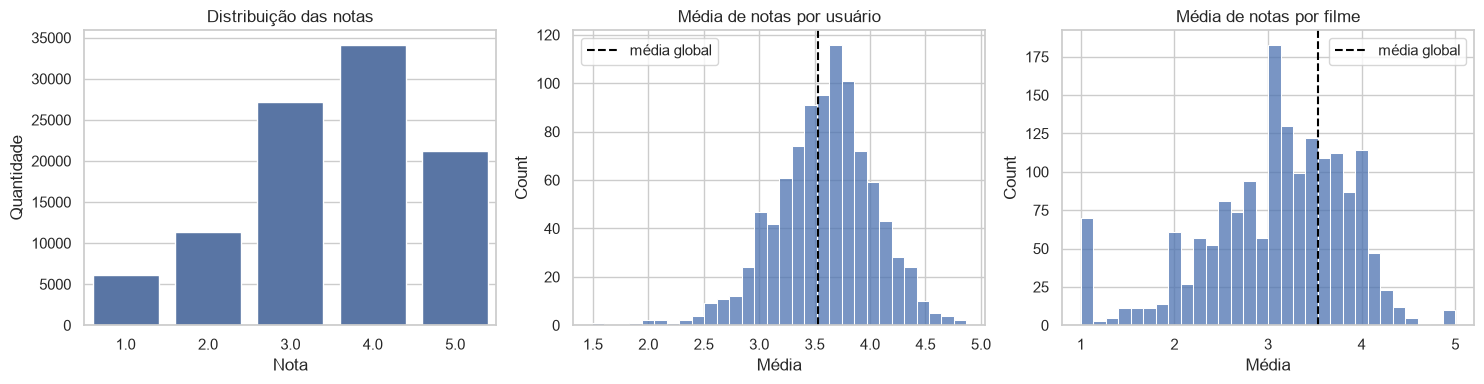

In [8]:
# Distribuição das notas
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=ratings, x="rating", ax=axes[0])
axes[0].set_title("Distribuição das notas")
axes[0].set_xlabel("Nota"); axes[0].set_ylabel("Quantidade")

sns.histplot(user_stats["mean"], bins=30, ax=axes[1])
axes[1].axvline(ratings["rating"].mean(), color="black", ls="--", label="média global")
axes[1].set_title("Média de notas por usuário")
axes[1].set_xlabel("Média"); axes[1].legend()

sns.histplot(item_stats["mean"], bins=30, ax=axes[2])
axes[2].axvline(ratings["rating"].mean(), color="black", ls="--", label="média global")
axes[2].set_title("Média de notas por filme")
axes[2].set_xlabel("Média"); axes[2].legend()

fig.tight_layout(); plt.show()

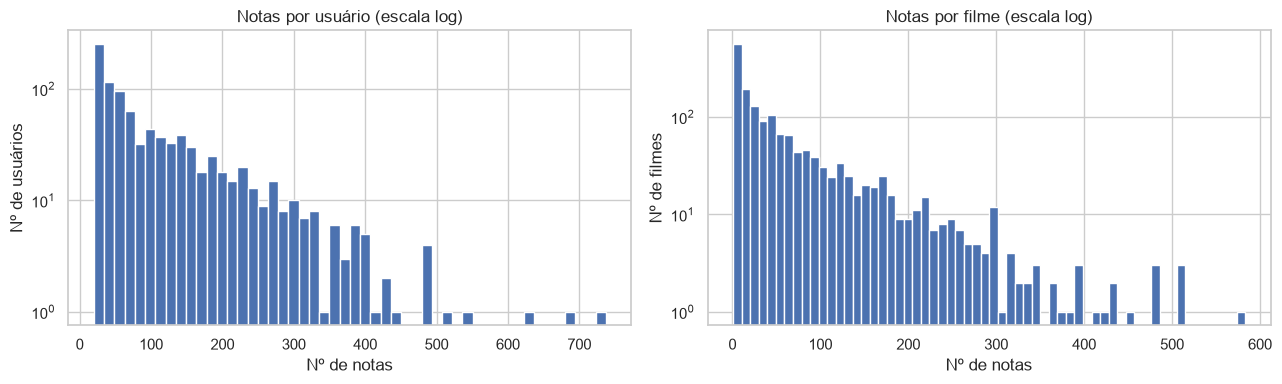

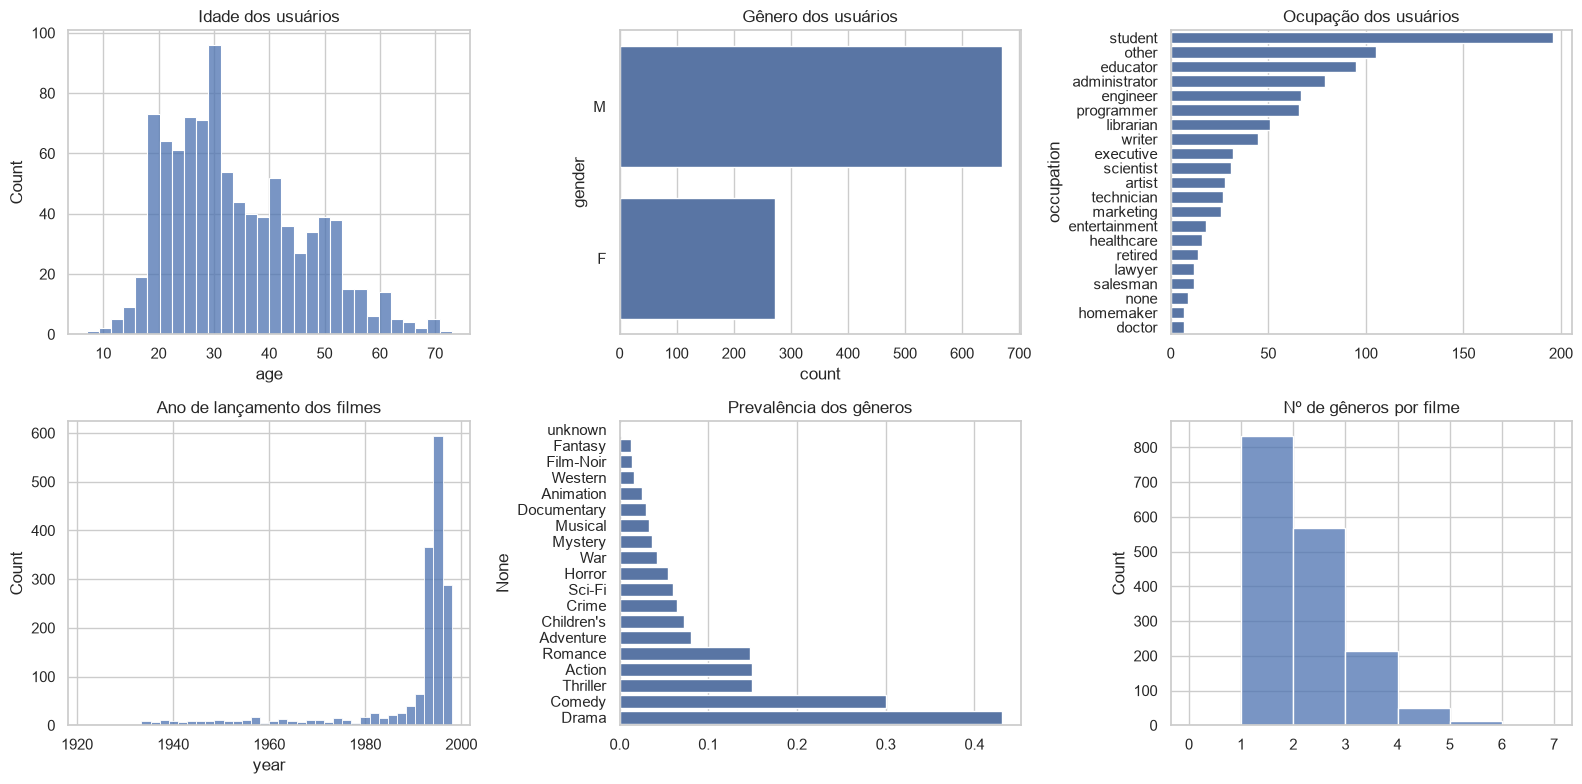

Filmes mais avaliados:


,count,mean,std,title,year
item_id,,,,,
49,583,4.358490,0.881341,Star Wars (1977),1977.0
257,509,3.803536,0.994427,Contact (1997),1997.0
99,508,4.155512,0.975756,Fargo (1996),1996.0
180,507,4.007890,0.923955,Return of the Jedi (1983),1983.0
293,485,3.156701,1.098544,Liar Liar (1997),1997.0
285,481,3.656965,1.169401,"English Patient, The (1996)",1996.0
287,478,3.441423,1.113910,Scream (1996),1996.0
0,452,3.878319,0.927897,Toy Story (1995),1995.0
299,431,3.631090,0.998072,Air Force One (1997),1997.0


Filmes com maiores médias (mínimo 50 notas):


,count,mean,std,title,year
item_id,,,,,
407,112,4.491071,0.771047,"Close Shave, A (1995)",1995.0
317,298,4.466443,0.829109,Schindler's List (1993),1993.0
168,118,4.466102,0.823607,"Wrong Trousers, The (1993)",1993.0
482,243,4.456790,0.728114,Casablanca (1942),1942.0
113,67,4.447761,0.764429,Wallace & Gromit: The Best of Aardman Animatio...,1996.0
63,283,4.445230,0.767008,"Shawshank Redemption, The (1994)",1994.0
602,209,4.387560,0.712551,Rear Window (1954),1954.0
11,267,4.385768,0.825500,"Usual Suspects, The (1995)",1995.0
49,583,4.358490,0.881341,Star Wars (1977),1977.0


Filmes com piores médias (mínimo 50 notas):


,count,mean,std,title,year
item_id,,,,,
930,57,2.157895,0.902169,"Island of Dr. Moreau, The (1996)",1996.0
686,69,2.188406,1.115075,McHale's Navy (1997),1997.0
119,67,2.238806,1.102196,Striptease (1996),1996.0
987,86,2.313953,1.108912,"Beautician and the Beast, The (1997)",1997.0
121,106,2.339623,1.111728,"Cable Guy, The (1996)",1996.0
449,63,2.396825,1.171430,Star Trek V: The Final Frontier (1989),1989.0
411,93,2.397850,1.133864,"Very Brady Sequel, A (1996)",1996.0
870,75,2.400000,1.039750,Vegas Vacation (1997),1997.0
242,132,2.439394,1.154200,Jungle2Jungle (1997),1997.0


,train,test
n_ratings,80696.000000,19304.000000
n_users,943.000000,942.000000
n_items,1682.000000,1349.000000
rating_mean,3.529456,3.531548
rating_std,1.126598,1.121828


Usuários ausentes no treino: 0
Filmes ausentes no treino: 0


count    942.000000
mean      20.492569
std       19.649518
min        3.000000
25%        6.000000
50%       12.000000
75%       29.000000
max      134.000000
Name: notas de teste por usuário, dtype: float64

In [9]:
# Atividade e cauda longa 
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(user_stats["count"], bins=50)
axes[0].set_yscale("log")
axes[0].set_title("Notas por usuário (escala log)")
axes[0].set_xlabel("Nº de notas"); axes[0].set_ylabel("Nº de usuários")

axes[1].hist(item_stats["count"], bins=60)
axes[1].set_yscale("log")
axes[1].set_title("Notas por filme (escala log)")
axes[1].set_xlabel("Nº de notas"); axes[1].set_ylabel("Nº de filmes")

fig.tight_layout(); plt.show()

# Metadados
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

sns.histplot(users["age"], bins=30, ax=axes[0, 0])
axes[0, 0].set_title("Idade dos usuários")

sns.countplot(data=users, y="gender", ax=axes[0, 1],
              order=users["gender"].value_counts().index)
axes[0, 1].set_title("Gênero dos usuários")

occ = users["occupation"].value_counts()
sns.barplot(x=occ.values, y=occ.index, ax=axes[0, 2])
axes[0, 2].set_title("Ocupação dos usuários")

sns.histplot(movies["year"].dropna(), bins=40, ax=axes[1, 0])
axes[1, 0].set_title("Ano de lançamento dos filmes")

genre_prev = movies[GENRES].mean().sort_values()
sns.barplot(x=genre_prev.values, y=genre_prev.index, ax=axes[1, 1])
axes[1, 1].set_title("Prevalência dos gêneros")

sns.histplot(movies[GENRES].sum(axis=1), bins=range(0, 8),
             ax=axes[1, 2])
axes[1, 2].set_title("Nº de gêneros por filme")

fig.tight_layout(); plt.show()

# Exemplos extremos
movie_info = movies.set_index("item_id")[["title", "year"]]

print("Filmes mais avaliados:")
display(item_stats.sort_values("count", ascending=False).head(10).join(movie_info))

min_count = 50
qualified = item_stats[item_stats["count"] >= min_count]
print(f"Filmes com maiores médias (mínimo {min_count} notas):")
display(qualified.sort_values("mean", ascending=False).head(10).join(movie_info))
print(f"Filmes com piores médias (mínimo {min_count} notas):")
display(qualified.sort_values("mean").head(10).join(movie_info))

# Sanidade do split
def split_summary(df: pd.DataFrame, name: str) -> pd.Series:
    return pd.Series({
        "n_ratings": len(df),
        "n_users": df["user_id"].nunique(),
        "n_items": df["item_id"].nunique(),
        "rating_mean": df["rating"].mean(),
        "rating_std": df["rating"].std(),
    }, name=name)

display(pd.concat([split_summary(train_df, "train"),
                   split_summary(test_df, "test")], axis=1))

print("Usuários ausentes no treino:", n_users - train_df["user_id"].nunique())
print("Filmes ausentes no treino:", n_items - train_df["item_id"].nunique())
display(test_df.groupby("user_id").size().describe().rename("notas de teste por usuário"))

## Etapa 1: Baselines

O primeiro passo para entender o problema é estabelecer uma baseline, um modelo simples que sirva como referência da performance que podemos esperar de um modelo mais sofisticado.
Podemos simplificar a formulação geral do problema, considerando apenas a média global das notas e os *biases* do usuário e do item, sem considerar os vetores latentes:

$$R_{ui} = \mu + b_u + b_i + \epsilon_{ui}$$

Como o modelo remove a interação entre usuários e itens, ele não é capaz de capturar a estrutura latente compartilhada entre eles, mas ainda assim pode fornecer uma boa referência para avaliar o desempenho de modelos mais complexos.
[Koren, Y. et. al.](https://ieeexplore.ieee.org/document/5197422) discute este exato modelo como uma aproximação de primeira ordem para o problema, que pode ser melhorada com a adição de termos de segunda ordem, como os vetores latentes introduzidos na formulação geral.
Recomenda-se a leitura do artigo para entender melhor a motivação e interpretação do problema e as soluções propostas.

Devido à linealidade do modelo,podemos aprender os *biases* do usuário e do item de forma eficiente, mesmo com a matriz de notas esparsa, através de regressão linear regularizada.

> **Tarefa 1.1**
> Treine o modelo de baseline e avalie seu desempenho, reportando RMSE e MAE no conjunto de teste.
> Lembre-se de usar o mesmo protocolo experimental para todos os modelos para encontrar o melhor conjunto de hiperparâmetros.
> Após treinar o modelo, analise os *biases* aprendidos e discuta o que eles podem nos dizer sobre a preferência dos usuários e a popularidade dos itens.

In [10]:
class BaselineModel:
    def __init__(
        self,
        user_reg: float = 10.0,
        item_reg: float = 10.0,
        n_epochs: int = 20,
    ) -> None:
        self.user_reg = user_reg
        self.item_reg = item_reg
        self.n_epochs = n_epochs

    def fit(self, train_df: pd.DataFrame) -> None:
        ratings = train_df["rating"].to_numpy(dtype=np.float64)
        users = train_df["user_id"].to_numpy(dtype=np.intp)
        items = train_df["item_id"].to_numpy(dtype=np.intp)

        self.global_mean = float(ratings.mean())
        self.user_bias = np.zeros(int(users.max()) + 1, dtype=np.float64)
        self.item_bias = np.zeros(int(items.max()) + 1, dtype=np.float64)

        n_users = len(self.user_bias)
        n_items = len(self.item_bias)

        user_counts = np.bincount(users, minlength=n_users)
        item_counts = np.bincount(items, minlength=n_items)

        for _ in range(self.n_epochs):
            # Os vieses de usuário e item são atualizados alternadamente, mantendo o outro fixo.
            # cada um resolve \min_b (sum_{(u,i) in R} (r_{ui} - mu - b_u - b_i)^2 + lambda * b^2)
            # Que é equivalente à agrupar por usuário e item, e então resolver a equação normal para cada um.

            user_residuals = ratings - self.global_mean - self.item_bias[items]
            self.user_bias = np.bincount(
                users, weights=user_residuals, minlength=n_users
            ) / (user_counts + self.user_reg)

            item_residuals = ratings - self.global_mean - self.user_bias[users]
            self.item_bias = np.bincount(
                items, weights=item_residuals, minlength=n_items
            ) / (item_counts + self.item_reg)

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.global_mean
            + self.user_bias[user_id]
            + self.item_bias[item_id]
        )

Melhores configurações (validação cruzada, 5 folds):


,user_reg,item_reg,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std
0,5.00,1.0,0.9436,0.0086,0.7452,0.0050
1,5.00,5.0,0.9437,0.0084,0.7466,0.0048
2,10.00,1.0,0.9439,0.0087,0.7464,0.0051
3,1.00,5.0,0.9440,0.0082,0.7460,0.0047
4,1.00,1.0,0.9440,0.0085,0.7445,0.0049
5,0.10,5.0,0.9442,0.0082,0.7460,0.0046
6,10.00,5.0,0.9442,0.0085,0.7478,0.0049
7,0.01,5.0,0.9442,0.0082,0.7460,0.0046
8,0.10,1.0,0.9443,0.0085,0.7445,0.0049
9,0.01,1.0,0.9443,0.0084,0.7445,0.0049


Hiperparâmetros escolhidos: {'user_reg': 5.0, 'item_reg': 1.0}


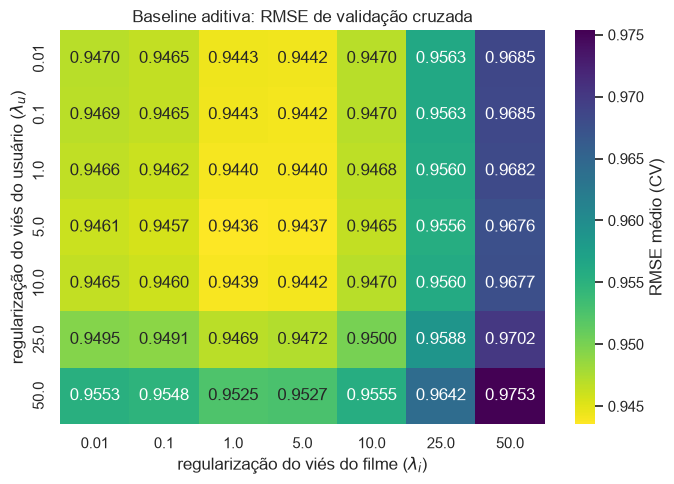

Desempenho no conjunto de teste:


,RMSE,RMSE IC95%,MAE,MAE IC95%
Média global,1.1218,-,0.9418,-
Baseline (viés usuário + filme),0.9355,"[0.9259, 0.9451]",0.7382,"[0.7305, 0.7463]"


RMSE treino = 0.9124; MAE treino = 0.7208
Correlações dos vieses com estatísticas observadas no treino:


,conjunto,variável,pearson,spearman,n
0,usuários,mean_rating,0.8623,0.8425,943
1,usuários,n_ratings,-0.1481,-0.1100,943
2,filmes,mean_rating,0.8584,0.9323,1682
3,filmes,n_ratings,0.3674,0.3256,1682


Resumo dos vieses aprendidos:


,b_u (usuários),b_i (filmes)
count,943.0000,1682.0000
mean,-0.0455,-0.1758
std,0.3721,0.5603
min,-1.6985,-1.7658
25%,-0.2638,-0.5333
50%,-0.0376,-0.1524
75%,0.1873,0.2317
max,1.3239,1.2550


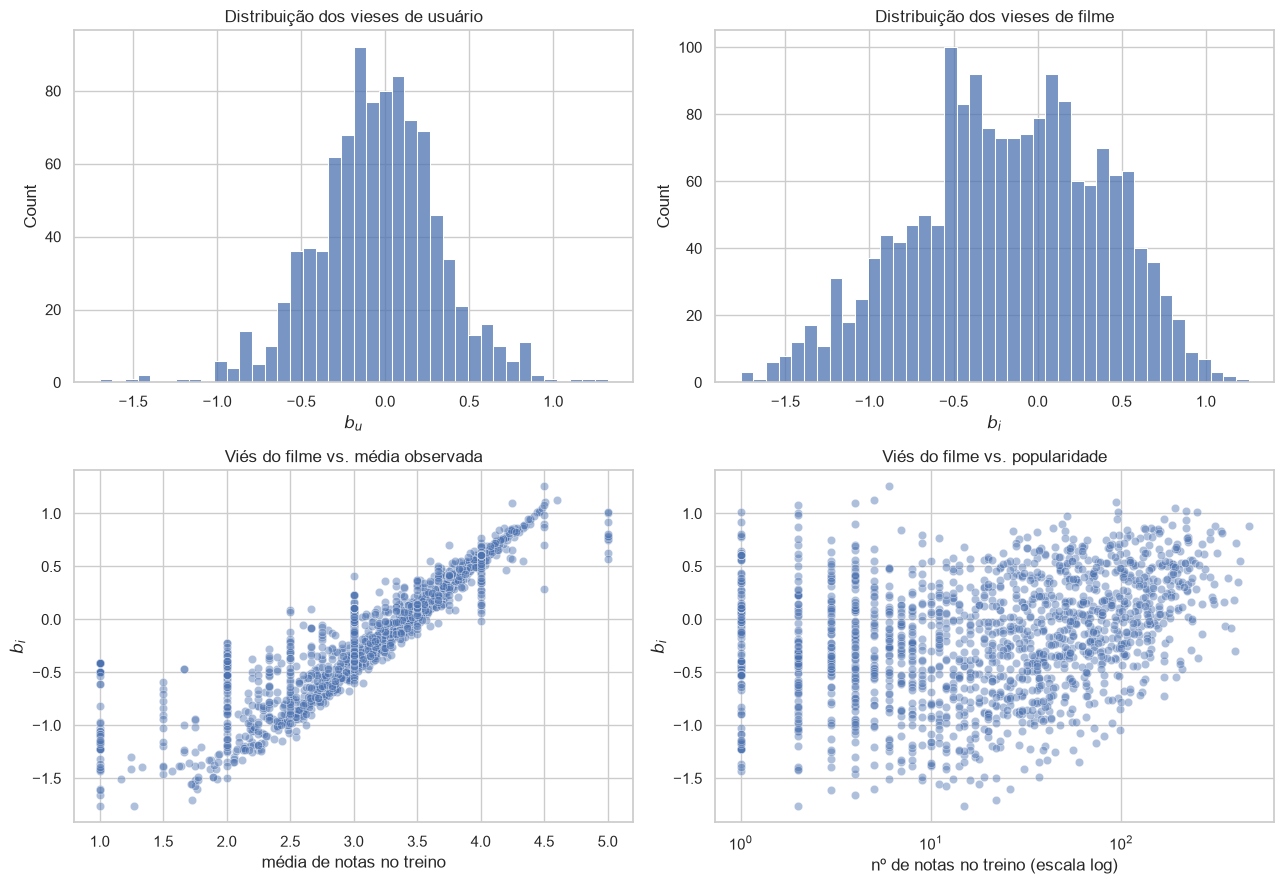

Filmes com maiores vieses:


,title,item_bias,mean_rating,n_ratings
1448,Pather Panchali (1955),1.255,4.500,6
1511,"World of Apu, The (Apur Sansar) (1959)",1.126,4.600,5
407,"Close Shave, A (1995)",1.110,4.511,94
1366,Faust (1994),1.102,4.250,4
1638,Bitter Sugar (Azucar Amargo) (1996),1.079,4.500,2
482,Casablanca (1942),1.047,4.487,193
63,"Shawshank Redemption, The (1994)",1.021,4.459,220
317,Schindler's List (1993),1.018,4.458,251
1535,Aiqing wansui (1994),1.016,5.000,1
168,"Wrong Trousers, The (1993)",1.016,4.448,96


Filmes com menores vieses:


,title,item_bias,mean_rating,n_ratings
1291,"Simple Wish, A (1997)",-1.766,1.000,2
423,Children of the Corn: The Gathering (1996),-1.760,1.267,15
367,Bio-Dome (1996),-1.707,1.727,22
313,3 Ninjas: High Noon At Mega Mountain (1998),-1.660,1.000,4
438,Amityville: A New Generation (1993),-1.609,1.000,3
456,Free Willy 3: The Rescue (1997),-1.601,1.769,26
436,Amityville 1992: It's About Time (1992),-1.600,1.000,5
1028,Jury Duty (1995),-1.572,1.750,12
668,Body Parts (1991),-1.554,1.727,11
1036,Grease 2 (1982),-1.550,1.722,18


Usuários com maiores vieses:


,user_bias,mean_rating,n_ratings
687,1.324,4.850,20
506,1.197,4.681,47
426,1.102,4.640,25
906,0.990,4.551,118
848,0.936,4.842,19
476,0.920,4.500,28
938,0.866,4.275,40
471,0.864,4.227,211
518,0.852,4.171,41
809,0.831,4.381,21


Usuários com menores vieses:


,user_bias,mean_rating,n_ratings
180,-1.698,1.430,365
404,-1.532,1.851,604
444,-1.468,2.046,108
773,-1.402,2.067,180
160,-1.225,2.532,47
205,-1.132,2.245,53
684,-1.011,1.938,16
723,-1.011,2.206,68
697,-0.967,2.931,102
625,-0.965,2.038,26


In [11]:
# Faça o treinamento e a avaliação do modelo baseline aqui

import itertools

from scipy.stats import spearmanr

# Dimensões globais do problema (fixas, conhecidas antes do treino).
N_USERS = int(ratings["user_id"].max()) + 1
N_ITEMS = int(ratings["item_id"].max()) + 1


def pad_biases(model: "BaselineModel") -> None:
    """Completa os vetores de viés para usuários/itens ausentes no treino.

    Um usuário ou filme sem nenhuma nota no treino fica com viés zero, ou seja,
    sua previsão é a média global.
    """
    model.user_bias = np.pad(
        model.user_bias, (0, max(0, N_USERS - len(model.user_bias)))
    )
    model.item_bias = np.pad(
        model.item_bias, (0, max(0, N_ITEMS - len(model.item_bias)))
    )


def make_user_folds(
    df: pd.DataFrame, n_folds: int = 5, seed: int = SEED
) -> NDArray[np.int8]:
    """Divide as notas em folds, estratificando por usuário.

    Cada usuário tem suas notas embaralhadas e distribuídas entre os folds,
    de modo que todos os usuários aparecem em todos os folds.
    """
    df = df.reset_index(drop=True)
    rng = np.random.default_rng(seed)
    folds = np.empty(len(df), dtype=np.int8)

    for positions in df.groupby("user_id").indices.values():
        positions = np.asarray(positions)
        order = rng.permutation(len(positions))
        folds[positions[order]] = np.arange(len(positions)) % n_folds

    return folds


def cross_validate(
    model_factory,
    train_df: pd.DataFrame,
    param_grid: dict[str, list],
    n_folds: int = 5,
    seed: int = SEED,
) -> pd.DataFrame:
    """Validação cruzada por usuário para uma grade de hiperparâmetros."""
    folds = make_user_folds(train_df, n_folds=n_folds, seed=seed)
    keys = list(param_grid)
    rows = []

    for values in itertools.product(*(param_grid[key] for key in keys)):
        params = dict(zip(keys, values))
        fold_metrics = []

        for fold in range(n_folds):
            fold_train = train_df.iloc[folds != fold]
            fold_valid = train_df.iloc[folds == fold]

            model = model_factory(**params)
            model.fit(fold_train)
            if isinstance(model, BaselineModel):
                pad_biases(model)
            fold_metrics.append(evaluate_model(model, validation=fold_valid))

        rows.append({
            **params,
            "cv_rmse_mean": np.mean([m["validation_rmse"] for m in fold_metrics]),
            "cv_rmse_std": np.std([m["validation_rmse"] for m in fold_metrics]),
            "cv_mae_mean": np.mean([m["validation_mae"] for m in fold_metrics]),
            "cv_mae_std": np.std([m["validation_mae"] for m in fold_metrics]),
        })

    return pd.DataFrame(rows).sort_values("cv_rmse_mean").reset_index(drop=True)


def bootstrap_ci(
    y_true: NDArray[np.float64],
    y_pred: NDArray[np.float64],
    n_boot: int = 1000,
    seed: int = SEED,
    alpha: float = 0.05,
) -> dict[str, tuple[float, float]]:
    """Intervalo de confiança bootstrap (percentil) para RMSE e MAE."""
    rng = np.random.default_rng(seed)
    squared_error = (y_true - y_pred) ** 2
    absolute_error = np.abs(y_true - y_pred)
    n = len(y_true)

    rmse = np.empty(n_boot)
    mae = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        rmse[b] = np.sqrt(squared_error[idx].mean())
        mae[b] = absolute_error[idx].mean()

    lower, upper = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "rmse": (np.percentile(rmse, lower), np.percentile(rmse, upper)),
        "mae": (np.percentile(mae, lower), np.percentile(mae, upper)),
    }


# ---------------------------------------------------------------------------
# 1) Escolha de hiperparâmetros por validação cruzada (somente no treino)
# ---------------------------------------------------------------------------
param_grid = {
    "user_reg": [0.01, 0.1, 1.0, 5.0, 10.0, 25.0, 50.0],
    "item_reg": [0.01, 0.1, 1.0, 5.0, 10.0, 25.0, 50.0],
}
N_FOLDS = 5
N_EPOCHS = 30

set_seed(SEED)
baseline_cv = cross_validate(
    lambda **params: BaselineModel(n_epochs=N_EPOCHS, **params),
    train_df,
    param_grid,
    n_folds=N_FOLDS,
    seed=SEED,
)

print("Melhores configurações (validação cruzada, 5 folds):")
display(baseline_cv.head(10).round(4))

best_params = {
    key: float(baseline_cv.loc[0, key]) for key in param_grid
}
print(f"Hiperparâmetros escolhidos: {best_params}")

# Mapa de calor do RMSE médio de validação
cv_pivot = baseline_cv.pivot(
    index="user_reg", columns="item_reg", values="cv_rmse_mean"
)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    cv_pivot, annot=True, fmt=".4f", cmap="viridis_r",
    cbar_kws={"label": "RMSE médio (CV)"}, ax=ax,
)
ax.set_xlabel("regularização do viés do filme ($\\lambda_i$)")
ax.set_ylabel("regularização do viés do usuário ($\\lambda_u$)")
ax.set_title("Baseline aditiva: RMSE de validação cruzada")
fig.tight_layout()
plt.show()

# ---------------------------------------------------------------------------
# 2) Treino final no treino completo e avaliação única no teste
# ---------------------------------------------------------------------------
set_seed(SEED)
baseline_model = BaselineModel(n_epochs=N_EPOCHS, **best_params)
baseline_model.fit(train_df)
pad_biases(baseline_model)

baseline_metrics = evaluate_model(baseline_model, train=train_df, test=test_df)

test_users = test_df["user_id"].to_numpy(dtype=np.intp)
test_items = test_df["item_id"].to_numpy(dtype=np.intp)
test_ratings = test_df["rating"].to_numpy(dtype=np.float64)
test_preds = clip_ratings(baseline_model.predict(test_users, test_items))
baseline_ci = bootstrap_ci(test_ratings, test_preds, seed=SEED)

# Referência ingênua: prever a média global do treino para todo mundo
global_mean_preds = np.full(len(test_ratings), baseline_model.global_mean)
global_mean_metrics = {
    "test_rmse": float(np.sqrt(np.mean((test_ratings - global_mean_preds) ** 2))),
    "test_mae": float(np.mean(np.abs(test_ratings - global_mean_preds))),
}

baseline_summary = pd.DataFrame(
    {
        "RMSE": [
            global_mean_metrics["test_rmse"],
            baseline_metrics["test_rmse"],
        ],
        "RMSE IC95%": [
            "-",
            f"[{baseline_ci['rmse'][0]:.4f}, {baseline_ci['rmse'][1]:.4f}]",
        ],
        "MAE": [
            global_mean_metrics["test_mae"],
            baseline_metrics["test_mae"],
        ],
        "MAE IC95%": [
            "-",
            f"[{baseline_ci['mae'][0]:.4f}, {baseline_ci['mae'][1]:.4f}]",
        ],
    },
    index=["Média global", "Baseline (viés usuário + filme)"],
)

print("Desempenho no conjunto de teste:")
display(baseline_summary.round(4))
print(
    f"RMSE treino = {baseline_metrics['train_rmse']:.4f}; "
    f"MAE treino = {baseline_metrics['train_mae']:.4f}"
)

# ---------------------------------------------------------------------------
# 3) Análise dos vieses aprendidos
# ---------------------------------------------------------------------------
user_bias_df = pd.DataFrame(
    {"user_bias": baseline_model.user_bias[:N_USERS]}
)
user_bias_df["mean_rating"] = train_df.groupby("user_id")["rating"].mean()
user_bias_df["n_ratings"] = train_df.groupby("user_id")["rating"].count()

item_bias_df = pd.DataFrame(
    {"item_bias": baseline_model.item_bias[:N_ITEMS]}
).join(movies.set_index("item_id"), how="inner")
item_bias_df["mean_rating"] = train_df.groupby("item_id")["rating"].mean()
item_bias_df["n_ratings"] = train_df.groupby("item_id")["rating"].count()

print("Correlações dos vieses com estatísticas observadas no treino:")
corr_rows = []
for name, df, target, features in [
    ("usuários", user_bias_df, "user_bias", ["mean_rating", "n_ratings"]),
    ("filmes", item_bias_df, "item_bias", ["mean_rating", "n_ratings"]),
]:
    for feature in features:
        sub = df[[target, feature]].dropna()
        corr_rows.append({
            "conjunto": name,
            "variável": feature,
            "pearson": sub[target].corr(sub[feature]),
            "spearman": spearmanr(sub[target], sub[feature]).statistic,
            "n": len(sub),
        })
display(pd.DataFrame(corr_rows).round(4))

bias_summary = pd.DataFrame({
    "b_u (usuários)": pd.Series(baseline_model.user_bias[:N_USERS]).describe(),
    "b_i (filmes)": pd.Series(baseline_model.item_bias[:N_ITEMS]).describe(),
})
print("Resumo dos vieses aprendidos:")
display(bias_summary.round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(user_bias_df["user_bias"], bins=40, ax=axes[0, 0])
axes[0, 0].set_title("Distribuição dos vieses de usuário")
axes[0, 0].set_xlabel("$b_u$")

sns.histplot(item_bias_df["item_bias"], bins=40, ax=axes[0, 1])
axes[0, 1].set_title("Distribuição dos vieses de filme")
axes[0, 1].set_xlabel("$b_i$")

sns.scatterplot(
    data=item_bias_df, x="mean_rating", y="item_bias",
    alpha=0.45, ax=axes[1, 0],
)
axes[1, 0].set_title("Viés do filme vs. média observada")
axes[1, 0].set_xlabel("média de notas no treino")
axes[1, 0].set_ylabel("$b_i$")

sns.scatterplot(
    data=item_bias_df, x="n_ratings", y="item_bias",
    alpha=0.45, ax=axes[1, 1],
)
axes[1, 1].set_xscale("log")
axes[1, 1].set_title("Viés do filme vs. popularidade")
axes[1, 1].set_xlabel("nº de notas no treino (escala log)")
axes[1, 1].set_ylabel("$b_i$")

fig.tight_layout()
plt.show()

print("Filmes com maiores vieses:")
display(
    item_bias_df.nlargest(10, "item_bias")[
        ["title", "item_bias", "mean_rating", "n_ratings"]
    ].round(3)
)
print("Filmes com menores vieses:")
display(
    item_bias_df.nsmallest(10, "item_bias")[
        ["title", "item_bias", "mean_rating", "n_ratings"]
    ].round(3)
)

print("Usuários com maiores vieses:")
display(
    user_bias_df.nlargest(10, "user_bias")[
        ["user_bias", "mean_rating", "n_ratings"]
    ].round(3)
)
print("Usuários com menores vieses:")
display(
    user_bias_df.nsmallest(10, "user_bias")[
        ["user_bias", "mean_rating", "n_ratings"]
    ].round(3)
)


**Discussão:**
Ajustamos o baseline com validação cruzada de 5 folds no conjunto de treino e avaliamos a grade pelo RMSE médio, obtendo a melhor configuração com:
- λ_u = 5
- λ_i = 1

No teste, o RMSE obtido foi de cerca de 0.9355, uma melhora de cerca de 0.18 com relação a média global (RMSE 1.1218). O MAE foi de cerca de 0.7382, vs. 0.9418 da média global.

Analisando os vieses obtidos a partir da baseline aditiva, podemos observar que:

- b_u (user_bias) parece representar a tendência de um usuário de avaliar os filmes acima ou abaixo da média global, independentemente do filme. Um b_u positivo parece indicar um usuário mais generoso, que costuma dar notas altas, enquanto um b_u negativo indica um usuário mais severo. Podemos observar que a corrrelação de Pearson entre b_u e a média de notas de cada usuário é forte (0.86), e a correlação entre b_u e o número de avaliações é bem baixa (-0.15), indicando ainda que esses resultados não tem relação com a quantidade de filmes assistidos. Por exemplo, o usuário 687 tem b_u = 1.32 e média 4.85, enquanto o usuário 180 tem b_u = -1.70 e média 1.43. Ou seja, b_u captura o "jeito de dar nota" do usuário.

- b_i (item_bias), similarmente, parece representar a tendência de um filme de receber notas acima ou abaixo da média. Um b_i positivo indica um filme bem avaliado de forma consistente, e um b_i negativo indica um filme mal avaliado. A relação com a média de notas do filme também é forte (0.86), e a relação com o número de avaliações é apenas moderada (0.37). É importante notar que filmes com poucas avaliações têm viés menos confiável, visto que a regularização puxa esses valores para perto de zero, mas ainda assim eles variam bastante. Além disso, b_i não é uma medida "pura" de qualidade, pois ele também depende de quais usuários avaliaram o filme.

Juntos, b_u e b_i explicam uma parte do erro em relação a prever apenas a média global, e o restante inclui tanto ruído quanto combinações específicas de usuário e filme que o modelo aditivo não consegue capturar.


---
### Introduzindo vetores latentes

A baseline linear captura diferenças sistemáticas entre usuários e itens, mas não explica por que determinados grupos de usuários atribuem notas semelhantes a determinados grupos de itens.
Para investigar essa estrutura, podemos olhar para a matriz de notas como um todo e perguntar se sua variabilidade pode ser explicada por um número reduzido de dimensões.
Essa perspectiva permite explorar interações globais nos dados e construir uma representação mais compacta das avaliações, codificando usuários e itens em um espaço latente compartilhado.

Uma maneira de investigar essa hipótese é completar a matriz de notas e aplicar Análise de Componentes Principais (PCA, *Principal Component Analysis*).
Para isso, substituímos as notas ausentes pela média do respectivo item, calculada apenas com as avaliações observadas no conjunto de treinamento.
Em seguida, o PCA identifica as principais direções de variação da matriz completada, permitindo representar cada usuário e cada item como vetores em um espaço de baixa dimensionalidade.

Seja $\tilde{R}$ a matriz de notas em que cada nota ausente foi substituída por um valor de imputação, por exemplo, a média do item.
O PCA com $k$ componentes aproxima $\tilde{R}$ por uma matriz de posto $k$:

$$\hat{R}_{ui} = \bar{R}_i + \mathbf{z}_u^\top \mathbf{w}_i$$

onde $\bar{R}_i$ é a média da coluna $i$ de $\tilde{R}$, $\mathbf{z}_u$ e $\mathbf{w}_i$ são as coordenadas do usuário $u$ e do item $i$ nos $k$ primeiros componentes principais.
Sob a perspectiva do PCA, um usuário é codificado como um vetor de pesos que indica a importância de cada componente principal para aquele usuário, que então é decodificado em uma nota para cada item, através da combinação linear com a transformação dos itens no mesmo espaço latente.

> **Tarefa 1.2**
Treine o modelo de PCA com imputação de notas ausentes, utilizando a média de cada item para preencher os valores faltantes. Utilize o protocolo experimental para selecionar o número de componentes principais $k$ e então reporte RMSE e MAE no conjunto de teste para o valor de $k$ selecionado.
>
> Analise e discuta também como o desempenho varia com o número de componentes, discutindo se o aumento da dimensionalidade melhora as previsões, produz ganhos decrescentes ou degrada o desempenho.


In [12]:
class ImputedPCA:
    def __init__(self, n_components: int = 10) -> None:
        self.n_components = n_components
        self.user_embeddings: NDArray[np.float64]
        self.item_embeddings: NDArray[np.float64]
        self.item_means: NDArray[np.float64]
        self.pca = PCA(n_components=n_components)

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)

        # Imputação de valores ausentes com a média do item
        observed = ~np.isnan(X)
        global_mean = float(X[observed].mean())
        counts = observed.sum(axis=0)
        sums = np.where(observed, X, 0.0).sum(axis=0)

        self.item_means = np.divide(
            sums,
            counts,
            out=np.full(X.shape[1], global_mean),
            where=counts > 0,
        )

        rows, cols = np.where(~observed)
        X[rows, cols] = self.item_means[cols]

        user_scores = self.pca.fit_transform(X)
        self.user_embeddings = user_scores
        self.item_embeddings = self.pca.components_.T

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.pca.mean_[item_id]
            + np.sum(
                self.user_embeddings[user_id]
                * self.item_embeddings[item_id],
                axis=1,
            )
        )

Melhor k: 10
RMSE de validação: 0.9930 ± 0.0084; MAE de validação: 0.7867 ± 0.0062


,n_components,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std
0,1,1.0086,0.0096,0.8022,0.0066
1,2,1.0060,0.0089,0.7993,0.0062
2,3,1.0003,0.0088,0.7940,0.0059
3,5,0.9963,0.0090,0.7905,0.0063
4,8,0.9932,0.0088,0.7872,0.0066
5,10,0.9930,0.0084,0.7867,0.0062
6,15,0.9946,0.0080,0.7877,0.0055
7,20,0.9963,0.0083,0.7887,0.0058
8,30,0.9995,0.0077,0.7918,0.0053
9,50,1.0058,0.0088,0.7979,0.0061


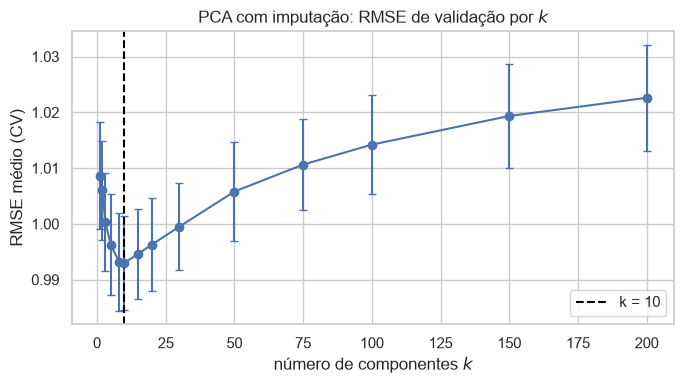

Desempenho no conjunto de teste:


,RMSE,RMSE IC95%,MAE,MAE IC95%
Baseline (vieses),0.9355,"[0.9259, 0.9451]",0.7382,"[0.7305, 0.7463]"
PCA imputado (k = 10),0.9735,"[0.9633, 0.9832]",0.7697,"[0.7615, 0.7781]"


RMSE treino = 0.8861; MAE treino = 0.6993


In [13]:
# Faça o treinamento e a avaliação do PCA imputado aqui

class ImputedPCAWithPadding(ImputedPCA):
    """ImputedPCA que mantém as dimensões globais do problema.

    Em alguns folds de validação, filmes com pouquíssimas notas podem ficar
    fora do treino. Nesse caso, completamos os vetores com zero e usamos a
    média global como previsão para esses filmes.
    """

    def fit(self, train_df: pd.DataFrame) -> None:
        super().fit(train_df)
        global_mean = float(train_df["rating"].mean())

        n_items_fit = self.item_embeddings.shape[0]
        if n_items_fit < N_ITEMS:
            pad = N_ITEMS - n_items_fit
            self.pca.mean_ = np.pad(
                self.pca.mean_, (0, pad), constant_values=global_mean
            )
            self.pca.components_ = np.pad(
                self.pca.components_, ((0, 0), (0, pad))
            )
            self.item_embeddings = np.pad(
                self.item_embeddings, ((0, pad), (0, 0))
            )
            self.item_means = np.pad(
                self.item_means, (0, pad), constant_values=global_mean
            )

        n_users_fit = self.user_embeddings.shape[0]
        if n_users_fit < N_USERS:
            self.user_embeddings = np.pad(
                self.user_embeddings,
                ((0, N_USERS - n_users_fit), (0, 0)),
            )


k_grid = [1, 2, 3, 5, 8, 10, 15, 20, 30, 50, 75, 100, 150, 200]

set_seed(SEED)
pca_cv = cross_validate(
    lambda n_components: ImputedPCAWithPadding(n_components=n_components),
    train_df,
    {"n_components": k_grid},
    n_folds=N_FOLDS,
    seed=SEED,
)

best_row = pca_cv.loc[pca_cv["cv_rmse_mean"].idxmin()]
best_k = int(best_row["n_components"])
print(f"Melhor k: {best_k}")
print(
    f"RMSE de validação: {best_row['cv_rmse_mean']:.4f} "
    f"± {best_row['cv_rmse_std']:.4f}; "
    f"MAE de validação: {best_row['cv_mae_mean']:.4f} "
    f"± {best_row['cv_mae_std']:.4f}"
)

pca_cv_sorted = pca_cv.sort_values("n_components").reset_index(drop=True)
display(pca_cv_sorted.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    pca_cv_sorted["n_components"],
    pca_cv_sorted["cv_rmse_mean"],
    yerr=pca_cv_sorted["cv_rmse_std"],
    marker="o", capsize=3,
)
ax.axvline(best_k, color="black", linestyle="--", label=f"k = {best_k}")
ax.set_xlabel("número de componentes $k$")
ax.set_ylabel("RMSE médio (CV)")
ax.set_title("PCA com imputação: RMSE de validação por $k$")
ax.legend()
fig.tight_layout()
plt.show()

# Treino final no treino completo e avaliação única no teste
set_seed(SEED)
pca_model = ImputedPCAWithPadding(n_components=best_k)
pca_model.fit(train_df)

pca_metrics = evaluate_model(pca_model, train=train_df, test=test_df)
pca_test_preds = clip_ratings(pca_model.predict(test_users, test_items))
pca_ci = bootstrap_ci(test_ratings, pca_test_preds, seed=SEED)

pca_summary = pd.DataFrame(
    {
        "RMSE": [
            baseline_metrics["test_rmse"],
            pca_metrics["test_rmse"],
        ],
        "RMSE IC95%": [
            f"[{baseline_ci['rmse'][0]:.4f}, {baseline_ci['rmse'][1]:.4f}]",
            f"[{pca_ci['rmse'][0]:.4f}, {pca_ci['rmse'][1]:.4f}]",
        ],
        "MAE": [
            baseline_metrics["test_mae"],
            pca_metrics["test_mae"],
        ],
        "MAE IC95%": [
            f"[{baseline_ci['mae'][0]:.4f}, {baseline_ci['mae'][1]:.4f}]",
            f"[{pca_ci['mae'][0]:.4f}, {pca_ci['mae'][1]:.4f}]",
        ],
    },
    index=["Baseline (vieses)", f"PCA imputado (k = {best_k})"],
)

print("Desempenho no conjunto de teste:")
display(pca_summary.round(4))
print(
    f"RMSE treino = {pca_metrics['train_rmse']:.4f}; "
    f"MAE treino = {pca_metrics['train_mae']:.4f}"
)


**Discussão:**
O melhor valor encontrado na validação cruzada foi k = 10. A curva de RMSE em função de k mostra uma melhora inicial, em que o erro cai de 1.0086 com k = 1 para 0.9930 com k = 10. A partir daí, os ganhos desaparecem e o desempenho começa a piorar, o que indica que poucos componentes não conseguem capturar a variação relevante dos dados (subajuste), enquanto muitos componentes passam a ajustar também o ruído e a estrutura artificial criada pela imputação (sobreajuste). O aumento do RMSE de treino para teste (0.8861 para 0.9735) reforça esse ponto.

Nos testes, o PCA com imputação obteve RMSE de cerca de 0.9735 e MAE de 0.7697, o que foi surpreendente pior que a baseline aditiva, embora continue melhor que prever a média global. Uma explicação para ficar atrás da baseline é que a imputação pela média do filme distorce a matriz de notas: todas as notas ausentes de um filme recebem o mesmo valor, o que reduz a variabilidade e faz usuários e filmes parecerem mais semelhantes do que realmente são. O PCA então pode aprender tanto a estrutura real das notas quanto a estrutura artificial criada pela imputação. Além disso, o modelo de PCA tem média por filme, mas não tem viés de usuário; a tendência de cada usuário de dar notas altas ou baixas precisa ser absorvida pelos vetores latentes, o que consome capacidade do modelo. 

Em resumo, aumentar k melhora as previsões até certo ponto (k = 10), mas depois traz ganhos decrescentes e passa a piorar o desempenho.


---

### Fatoração de matrizes (*Matrix Factorization*)

A principal limitação do modelo anterior é que ele depende de notas imputadas, que não correspondem a avaliações reais e podem introduzir vieses no aprendizado dos vetores latentes.
Para superar essa limitação, devemos aprender os vetores latentes diretamente a partir das notas observadas, sem precisar completar previamente a matriz.

A fatoração de matrizes parte da hipótese de que a matriz de notas pode ser aproximada pelo produto de duas matrizes de menor dimensão, ou seja

$$\hat R = Z W^\top,$$
em que $Z\in\mathbb R^{|U|\times k}$ e $W\in\mathbb R^{|I|\times k}$ contêm os vetores latentes dos usuários e dos itens, respectivamente.
Dessa forma, a nota prevista para um par usuário–item é dada pelo produto interno entre suas representações:

$$\hat R_{ui}=\mathbf z_u^\top\mathbf w_i.$$

Entretanto, como vimos na baseline, parte da variação das notas pode ser explicada por diferenças sistemáticas entre usuários e itens, independentemente de suas interações (por exemplo, alguns filmes são mais populares que outros).
Para considerar esses efeitos, incorporamos a média global e os *biases* de usuário e item ao modelo, obtendo a formulação geral com $f(\mathbf{z}_u, \mathbf{w}_i) = \mathbf z_u^\top\mathbf w_i$:

$$\hat R_{ui}=\mu+b_u+b_i+\mathbf z_u^\top\mathbf w_i.$$

Para aprender os parâmetros, minimizamos o erro quadrático entre as notas observadas e as respectivas previsões, considerando apenas os pares usuário–item avaliados no conjunto de treinamento.
Introduzimos também regularização $L_2$, que penaliza valores elevados dos *biases* e das normas dos vetores latentes:

\begin{aligned}
\min_{\mu,b,Z_U,Z_I}\quad
&\sum_{(u,i)\in\Omega}
\left(r_{ui}-\mu-b_u-b_i-\mathbf z_u^\top\mathbf w_i\right)^2\\
&+\lambda_b\left(\sum_u b_u^2+\sum_i b_i^2\right)\\
&+\lambda_z\left(\sum_u\|\mathbf z_u\|_2^2+
\sum_i\|\mathbf w_i\|_2^2\right),
\end{aligned}

em que $\Omega$ é o conjunto de avaliações observadas no treinamento, enquanto $\lambda_b$ e $\lambda_z$ controlam a intensidade da regularização dos *biases* e dos fatores latentes, respectivamente.
Como o problema é não-convexo, sem solução fechada, usamos descida no gradiente para atualizar os parâmetros, iterativamente com base em pequenas amostras do conjunto de treinamento.

> **Tarefa 1.3**
Treine um modelo de fatoração de matrizes utilizando regularização $L_2$.
Selecione o número de dimensões latentes $k$ e os coeficientes de regularização com base no RMSE.
> 
> Reporte RMSE e MAE no conjunto de teste para a configuração selecionada.
Analise como o desempenho varia com $k$ e com a regularização.
Por fim, compare a fatoração com *biases* e sem *biases*, mantendo o mesmo protocolo experimental, para investigar a contribuição dos efeitos aditivos e das interações latentes para a qualidade das previsões.
>
> Siga o mesmo protocolo experimental utilizado para os modelos anteriores.


In [14]:
class MatrixFactorization:
    user_embeddings: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    global_mean: float
    user_bias: NDArray[np.float64]
    item_bias: NDArray[np.float64]

    def __init__(
        self,
        n_factors: int = 10,
        n_epochs: int = 20,
        learning_rate: float = 0.01,
        reg: float = 0.1,
        bias_reg: float | None = None,
        use_biases: bool = True,
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.learning_rate = learning_rate
        self.reg = reg
        self.bias_reg = reg if bias_reg is None else bias_reg
        self.use_biases = use_biases

    def fit(self, train_df: pd.DataFrame) -> None:
        ratings = train_df["rating"].to_numpy(dtype=np.float64)
        users = train_df["user_id"].to_numpy(dtype=np.intp)
        items = train_df["item_id"].to_numpy(dtype=np.intp)

        self.global_mean = float(ratings.mean())
        n_users = int(users.max()) + 1
        n_items = int(items.max()) + 1

        self.user_embeddings = np.random.normal(scale=0.1, size=(n_users, self.n_factors))
        self.item_embeddings = np.random.normal(scale=0.1, size=(n_items, self.n_factors))
        self.user_bias = np.zeros(n_users, dtype=np.float64)
        self.item_bias = np.zeros(n_items, dtype=np.float64)

        for _ in range(self.n_epochs):
            for n in np.random.permutation(len(ratings)):
                u, i, r = users[n], items[n], ratings[n]
                pred = (
                    self.global_mean
                    + self.user_bias[u]
                    + self.item_bias[i]
                    + np.dot(self.user_embeddings[u], self.item_embeddings[i])
                )
                err = r - pred

                # Atualização dos vieses
                if self.use_biases:
                    self.user_bias[u] += self.learning_rate * (err - self.bias_reg * self.user_bias[u])
                    self.item_bias[i] += self.learning_rate * (err - self.bias_reg * self.item_bias[i])

                user_emb_old = self.user_embeddings[u].copy()
                item_emb_old = self.item_embeddings[i].copy()

                self.user_embeddings[u] += self.learning_rate * (err * item_emb_old - self.reg * user_emb_old)
                self.item_embeddings[i] += self.learning_rate * (err * user_emb_old - self.reg * item_emb_old)

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.global_mean
            + self.user_bias[user_id]
            + self.item_bias[item_id]
            + np.sum(
                self.user_embeddings[user_id] * self.item_embeddings[item_id],
                axis=1,
            )
        )


In [15]:
# Faça o treinamento e a avaliação do modelo de fatoração de matrizes aqui

class MatrixFactorizationWithPadding(MatrixFactorization):
    """MatrixFactorization que mantém as dimensões globais do problema.

    Em alguns folds de validação, filmes com pouquíssimas notas podem ficar
    fora do treino. Nesse caso, completamos embeddings e vieses com zero,
    de modo que a previsão para esses filmes seja a média global.
    """

    def fit(self, train_df: pd.DataFrame) -> None:
        super().fit(train_df)

        n_users_fit = self.user_embeddings.shape[0]
        if n_users_fit < N_USERS:
            pad = N_USERS - n_users_fit
            self.user_embeddings = np.pad(
                self.user_embeddings, ((0, pad), (0, 0))
            )
            self.user_bias = np.pad(self.user_bias, (0, pad))

        n_items_fit = self.item_embeddings.shape[0]
        if n_items_fit < N_ITEMS:
            pad = N_ITEMS - n_items_fit
            self.item_embeddings = np.pad(
                self.item_embeddings, ((0, pad), (0, 0))
            )
            self.item_bias = np.pad(self.item_bias, (0, pad))


def make_mf(**params):
    """Cria um MF com semente fixa, para reprodutibilidade do SGD."""
    set_seed(SEED)
    return MatrixFactorizationWithPadding(**params)


MF_EPOCHS = 15
MF_LR = 0.02
MF_K_GRID = [50, 100, 200]
MF_REG_GRID = [0.1, 0.5]

# Etapa 1: escolha de k com as regularizações fixas em 0.1.
set_seed(SEED)
mf_k_cv = cross_validate(
    make_mf,
    train_df,
    {
        "n_factors": MF_K_GRID,
        "n_epochs": [MF_EPOCHS],
        "learning_rate": [MF_LR],
        "reg": [0.1],
        "bias_reg": [0.1],
        "use_biases": [True],
    },
    n_folds=N_FOLDS,
    seed=SEED,
)

mf_best_k = int(mf_k_cv.loc[0, "n_factors"])
print(f"Melhor k (com regularizações em 0.1): {mf_best_k}")
display(mf_k_cv.round(4))

# Etapa 2: no melhor k, variar as regularizações.
set_seed(SEED)
mf_reg_cv = cross_validate(
    make_mf,
    train_df,
    {
        "n_factors": [mf_best_k],
        "n_epochs": [MF_EPOCHS],
        "learning_rate": [MF_LR],
        "reg": MF_REG_GRID,
        "bias_reg": MF_REG_GRID,
        "use_biases": [True],
    },
    n_folds=N_FOLDS,
    seed=SEED,
)

mf_best_row = mf_reg_cv.loc[0]
mf_best_lambda_z = float(mf_best_row["reg"])
mf_best_lambda_b = float(mf_best_row["bias_reg"])
print(
    f"Melhores regularizações: lambda_b = {mf_best_lambda_b}, "
    f"lambda_z = {mf_best_lambda_z}"
)
print(
    f"RMSE de validação: {mf_best_row['cv_rmse_mean']:.4f} "
    f"± {mf_best_row['cv_rmse_std']:.4f}; "
    f"MAE de validação: {mf_best_row['cv_mae_mean']:.4f} "
    f"± {mf_best_row['cv_mae_std']:.4f}"
)
display(mf_reg_cv.round(4))

# Treino final com vieses.
set_seed(SEED)
mf_model = MatrixFactorizationWithPadding(
    n_factors=mf_best_k,
    n_epochs=MF_EPOCHS,
    learning_rate=MF_LR,
    reg=mf_best_lambda_z,
    bias_reg=mf_best_lambda_b,
    use_biases=True,
)
mf_model.fit(train_df)

mf_metrics = evaluate_model(mf_model, train=train_df, test=test_df)
mf_test_preds = clip_ratings(mf_model.predict(test_users, test_items))
mf_ci = bootstrap_ci(test_ratings, mf_test_preds, seed=SEED)

# Treino final sem vieses, com o mesmo k e a mesma regularização.
set_seed(SEED)
mf_nobias_model = MatrixFactorizationWithPadding(
    n_factors=mf_best_k,
    n_epochs=MF_EPOCHS,
    learning_rate=MF_LR,
    reg=mf_best_lambda_z,
    bias_reg=mf_best_lambda_b,
    use_biases=False,
)
mf_nobias_model.fit(train_df)

mf_nobias_metrics = evaluate_model(mf_nobias_model, train=train_df, test=test_df)
mf_nobias_test_preds = clip_ratings(
    mf_nobias_model.predict(test_users, test_items)
)
mf_nobias_ci = bootstrap_ci(
    test_ratings, mf_nobias_test_preds, seed=SEED
)

# Validação cruzada do modelo sem vieses, no mesmo protocolo.
set_seed(SEED)
mf_nobias_cv = cross_validate(
    make_mf,
    train_df,
    {
        "n_factors": [mf_best_k],
        "n_epochs": [MF_EPOCHS],
        "learning_rate": [MF_LR],
        "reg": [mf_best_lambda_z],
        "bias_reg": [mf_best_lambda_b],
        "use_biases": [False],
    },
    n_folds=N_FOLDS,
    seed=SEED,
)

mf_nobias_row = mf_nobias_cv.loc[0]
print(
    f"MF sem vieses: RMSE de validação = "
    f"{mf_nobias_row['cv_rmse_mean']:.4f} ± "
    f"{mf_nobias_row['cv_rmse_std']:.4f}; MAE = "
    f"{mf_nobias_row['cv_mae_mean']:.4f} ± "
    f"{mf_nobias_row['cv_mae_std']:.4f}"
)

mf_summary = pd.DataFrame(
    {
        "RMSE": [
            baseline_metrics["test_rmse"],
            pca_metrics["test_rmse"],
            mf_nobias_metrics["test_rmse"],
            mf_metrics["test_rmse"],
        ],
        "RMSE IC95%": [
            f"[{baseline_ci['rmse'][0]:.4f}, {baseline_ci['rmse'][1]:.4f}]",
            f"[{pca_ci['rmse'][0]:.4f}, {pca_ci['rmse'][1]:.4f}]",
            f"[{mf_nobias_ci['rmse'][0]:.4f}, {mf_nobias_ci['rmse'][1]:.4f}]",
            f"[{mf_ci['rmse'][0]:.4f}, {mf_ci['rmse'][1]:.4f}]",
        ],
        "MAE": [
            baseline_metrics["test_mae"],
            pca_metrics["test_mae"],
            mf_nobias_metrics["test_mae"],
            mf_metrics["test_mae"],
        ],
        "MAE IC95%": [
            f"[{baseline_ci['mae'][0]:.4f}, {baseline_ci['mae'][1]:.4f}]",
            f"[{pca_ci['mae'][0]:.4f}, {pca_ci['mae'][1]:.4f}]",
            f"[{mf_nobias_ci['mae'][0]:.4f}, {mf_nobias_ci['mae'][1]:.4f}]",
            f"[{mf_ci['mae'][0]:.4f}, {mf_ci['mae'][1]:.4f}]",
        ],
    },
    index=[
        "Baseline (vieses)",
        f"PCA imputado (k = {pca_model.n_components})",
        f"MF sem vieses (k = {mf_best_k})",
        f"MF com vieses (k = {mf_best_k})",
    ],
)

print("Desempenho no conjunto de teste:")
display(mf_summary.round(4))
print(
    f"MF com vieses: RMSE treino = {mf_metrics['train_rmse']:.4f}; "
    f"MAE treino = {mf_metrics['train_mae']:.4f}"
)
print(
    f"MF sem vieses: RMSE treino = {mf_nobias_metrics['train_rmse']:.4f}; "
    f"MAE treino = {mf_nobias_metrics['train_mae']:.4f}"
)

# ---------------------------------------------------------------------------
# Métricas de lista
# ---------------------------------------------------------------------------

def ranking_metrics(
    model,
    train_df: pd.DataFrame,
    test_df: pd.DataFrame,
    k: int = 10,
    threshold: float = 4.0,
) -> dict[str, float]:
    """Precision@k, HitRate@k e NDCG@k para um modelo de previsão de notas.

    Um item de teste é considerado relevante se sua nota for >= threshold.
    Os candidatos são todos os filmes que o usuário não avaliou no treino.
    Avaliamos apenas usuários com pelo menos um item relevante no teste.
    """
    train_items = (
        train_df.groupby("user_id")["item_id"].apply(set).to_dict()
    )
    relevant_items = (
        test_df[test_df["rating"] >= threshold]
        .groupby("user_id")["item_id"]
        .apply(set)
        .to_dict()
    )

    all_items = np.arange(N_ITEMS)
    precisions, hit_rates, ndcgs = [], [], []

    for user, relevant in relevant_items.items():
        seen = train_items.get(user, set())
        candidates = np.array(
            [item for item in all_items if item not in seen],
            dtype=np.intp,
        )

        scores = model.predict(
            np.full(len(candidates), user, dtype=np.intp),
            candidates,
        )
        top_k = candidates[np.argsort(-scores, kind="stable")[:k]]

        hits = np.isin(top_k, list(relevant))
        precisions.append(hits.sum() / k)
        hit_rates.append(float(hits.any()))

        dcg = np.sum(hits / np.log2(np.arange(2, len(hits) + 2)))
        ideal = np.sum(
            1.0 / np.log2(np.arange(2, min(k, len(relevant)) + 2))
        )
        ndcgs.append(dcg / ideal if ideal > 0 else 0.0)

    return {
        "Precision@10": float(np.mean(precisions)),
        "HitRate@10": float(np.mean(hit_rates)),
        "NDCG@10": float(np.mean(ndcgs)),
        "n_usuarios": len(precisions),
    }


ranking_results = pd.DataFrame(
    {
        "Baseline (vieses)": ranking_metrics(
            baseline_model, train_df, test_df
        ),
        "PCA imputado": ranking_metrics(pca_model, train_df, test_df),
        "MF sem vieses": ranking_metrics(
            mf_nobias_model, train_df, test_df
        ),
        "MF com vieses": ranking_metrics(mf_model, train_df, test_df),
    }
).T

print(
    "Métricas de lista (acerto: nota de teste >= 4; "
    "candidatos: filmes não avaliados no treino):"
)
display(ranking_results.round(4))


Melhor k (com regularizações em 0.1): 200


,n_factors,n_epochs,learning_rate,reg,bias_reg,use_biases,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std
0,200,15,0.02,0.1,0.1,True,0.9243,0.0076,0.7320,0.0048
1,100,15,0.02,0.1,0.1,True,0.9247,0.0087,0.7319,0.0053
2,50,15,0.02,0.1,0.1,True,0.9260,0.0085,0.7326,0.0045


Melhores regularizações: lambda_b = 0.1, lambda_z = 0.1
RMSE de validação: 0.9243 ± 0.0076; MAE de validação: 0.7320 ± 0.0048


,n_factors,n_epochs,learning_rate,reg,bias_reg,use_biases,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std
0,200,15,0.02,0.1,0.1,True,0.9243,0.0076,0.7320,0.0048
1,200,15,0.02,0.1,0.5,True,0.9397,0.0077,0.7505,0.0051
2,200,15,0.02,0.5,0.1,True,0.9471,0.0084,0.7507,0.0051
3,200,15,0.02,0.5,0.5,True,0.9642,0.0083,0.7741,0.0053


MF sem vieses: RMSE de validação = 0.9552 ± 0.0073; MAE = 0.7602 ± 0.0051
Desempenho no conjunto de teste:


,RMSE,RMSE IC95%,MAE,MAE IC95%
Baseline (vieses),0.9355,"[0.9259, 0.9451]",0.7382,"[0.7305, 0.7463]"
PCA imputado (k = 10),0.9735,"[0.9633, 0.9832]",0.7697,"[0.7615, 0.7781]"
MF sem vieses (k = 200),0.9276,"[0.9185, 0.9370]",0.7346,"[0.7272, 0.7428]"
MF com vieses (k = 200),0.9084,"[0.8990, 0.9181]",0.7161,"[0.7086, 0.7240]"


MF com vieses: RMSE treino = 0.6969; MAE treino = 0.5548
MF sem vieses: RMSE treino = 0.6861; MAE treino = 0.5501


Métricas de lista (acerto: nota de teste >= 4; candidatos: filmes não avaliados no treino):


,Precision@10,HitRate@10,NDCG@10,n_usuarios
Baseline (vieses),0.0207,0.1765,0.0183,929.0
PCA imputado,0.0025,0.0205,0.0044,929.0
MF sem vieses,0.0856,0.4543,0.1009,929.0
MF com vieses,0.0672,0.3950,0.0753,929.0


**Discussão:**
Seguindo o mesmo protocolo dos modelos anteriores, treinamos a fatoração de matrizes por SGD usando apenas os pares observados no treino, sem imputação, com mu fixada na média do treino. Pela validação cruzada, o melhor k foi 200 e as melhores regularizações foram lambda_b = 0.1 e lambda_z = 0.1. 

Nos testes, essa configuração obteve RMSE 0.9084 e MAE 0.7161.

O desempenho praticamente satura com k, visto que o RMSE de validação vai de 0.9247 com k = 100 para 0.9243 com k = 200, então aumentar mais só deve ajustar ruído. Observamos também que a regularização forte demais parece provocar um sobreajuste, obtendo melhores resultados com as duas em 0.1. Na comparação com e sem vieses, o modelo com vieses foi melhor tanto na validação (0.9243 vs 0.9552) quanto no teste (0.9084 vs 0.9276), indicando que os efeitos aditivos de usuário e filme contribuem no geral. Já as interações latentes aparecem ao comparar a baseline aditiva (0.9355) com a MF com vieses (0.9084). 

Para as métricas de lista, consideramos acerto um filme de teste com nota maior ou igual a 4, e candidatos todos os filmes que o usuário não avaliou no treino. Avaliamos apenas os usuários com pelo menos um filme relevante no teste. Podemos observar os resultados e a comparação entre as métricas nessa última tabela do output da célula acima. Nela, podemos observar que a MF com vieses tem o melhor RMSE (0.9084), mas a MF sem vieses, com RMSE um pouco pior (0.9276), é melhor em todas as métricas de lista (HitRate@10 de 0.4543 vs. 0.3950, e NDCG@10 de 0.1009 vs. 0.0753). O motivo para isso pode ser o fato de que o RMSE mede o erro das notas nos pares observados do teste, enquanto a lista depende da ordem dos filmes não avaliados. Com vieses, boa parte da nota vem de b_i, que é igual para todos os usuários, então o top 10 tende a ser parecido para todo mundo, enquanto sem vieses, a ordenação depende mais do produto interno entre z_u e w_i, que varia de usuário para usuário, gerando listas mais personalizadas. Assim, tendo em vista essas observações, o modelo com menor RMSE não parece ser o que gera as melhores listas.


---
## Etapa 2: Suposições sobre a estrutura latente

Na etapa anterior, investigamos modelos que estimam notas a partir de vieses aditivos e representações latentes de usuários e itens.
A fatoração de matrizes procura representações que aproximem as avaliações observadas, mas não define, por si só, uma distribuição probabilística completa para os dados.

Nesta etapa, exploraremos uma abordagem probabilística baseada no PCA Probabilístico (*Probabilistic Principal Component Analysis*, PPCA), adaptada ao problema de recomendação.
Essa formulação descreve as avaliações por meio de variáveis latentes e ruído gaussiano, permitindo explicitar a variância do ruído, estimar a verossimilhança dos dados e investigar como as suposições probabilísticas afetam as previsões.

Ao contrário das implementações clássicas de PPCA e VAE, em que o encoder é treinado para mapear as observações para a distribuição posterior, aqui, como os usuários do conjunto de dados são conhecidos durante o treinamento, podemos estimar um embedding para cada um deles e armazenar essas representações após o ajuste do modelo.
Isso é equivalente a um *encoder* que mapeia cada usuário para uma distribuição posterior com o máximo de liberdade, sem lidar com features de usuário, vieses indutivos ou generalização para novos usuários.


### PCA Probabilístico

O PCA clássico identifica um subespaço linear de dimensão reduzida que representa a estrutura de variância dos dados. O PPCA estende essa ideia ao assumir que as observações são geradas por transformações lineares de variáveis latentes gaussianas, acrescidas de ruído gaussiano.

No problema de recomendação, podemos representar a matriz de avaliações por $R\in\mathbb R^{n\times m}$, em que $n$ é o número de usuários e $m$ é o número de filmes. Cada usuário corresponde a uma observação, e cada filme corresponde a uma dimensão observada. Como os usuários do conjunto de dados são conhecidos durante o treinamento, podemos estimar um embedding para cada um deles e armazenar essas representações após o ajuste do modelo.

Seja $\mathbf z_u\in\mathbb R^k$ a variável latente do usuário $u$, e seja $\mathbf w_i\in\mathbb R^k$ o vetor de cargas associado ao filme $i$. O modelo assume que

$$
\mathbf z_u\sim\mathcal N(\mathbf 0,I_k)
$$

e que a avaliação do usuário $u$ para o filme $i$ segue

$$
R_{ui}\mid\mathbf z_u
\sim
\mathcal N\left(
\mu_i+\mathbf z_u^\top\mathbf w_i,
\sigma^2
\right),
$$

em que $\mu_i$ é a média associada ao filme $i$, $k$ é a dimensão latente e $\sigma^2$ é a variância do ruído, considerada fixa durante o treinamento.
A média condicional da avaliação é, portanto,

$$
\mathbb E[R_{ui}\mid\mathbf z_u]
=
\mu_i+\mathbf z_u^\top\mathbf w_i.
$$

Essa formulação representa as avaliações por meio de uma estrutura linear de baixa dimensão, sem introduzir vieses aditivos específicos de usuários.
A diferença fundamental em relação à fatoração de matrizes determinística está na distribuição probabilística atribuída às avaliações e às variáveis latentes.

O treinamento pode ser realizado pelo algoritmo EM (*Expectation-Maximization*).
Seja $\Omega_u$ o conjunto de filmes avaliados pelo usuário $u$ e $\Omega_i$ o conjunto de usuários que avaliaram o filme $i$.
Na etapa E, como o modelo é linear e gaussiano, a posterior de cada usuário, condicionada às avaliações observadas e aos parâmetros atuais, é gaussiana, $p(\mathbf z_u\mid R_u)=\mathcal N(\mathbf m_u, S_u)$, com

$$
S_u=\left( I_k + \frac{1}{\sigma^2} \sum_{i\in\Omega_u} \mathbf w_i\mathbf w_i^\top\right)^{-1},
\qquad
\mathbf m_u=\frac{1}{\sigma^2} \, S_u\sum_{i\in\Omega_u}\mathbf w_i\,(r_{ui}-\mu_i).
$$

Na etapa M, atualizamos as médias dos filmes e os vetores de cargas para maximizar a verossimilhança esperada.
Definindo $\boldsymbol\theta_i=(\mu_i,\mathbf w_i)$ e $\boldsymbol\phi_u=(1,\mathbf z_u)$, cada filme resolve um sistema de mínimos quadrados em que as posteriores entram pelos momentos $\mathbb E[\boldsymbol\phi_u]=(1,\mathbf m_u)$ e $\mathbb E[\mathbf z_u\mathbf z_u^\top]=S_u+\mathbf m_u\mathbf m_u^\top$:

$$
\boldsymbol\theta_i=\left(\sum_{u\in\Omega_i}\mathbb E[\boldsymbol\phi_u\boldsymbol\phi_u^\top]\right)^{-1}\sum_{u\in\Omega_i}r_{ui}\,\mathbb E[\boldsymbol\phi_u].
$$

Como a matriz de avaliações é esparsa, cada usuário contribui para a estimação apenas por meio dos filmes que avaliou. As avaliações ausentes são tratadas como dados não observados, e não como notas iguais a zero. Após o treinamento, as médias dos embeddings posteriores podem ser armazenadas como representações dos usuários, permitindo realizar previsões diretamente para os pares usuário–filme.

Para uma avaliação observada $r_{ui}$, a densidade condicional é

$$
p(r_{ui}\mid\mathbf z_u)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{
(r_{ui}-\mu_i-\mathbf w_i^\top\mathbf z_u)^2
}{2\sigma^2}
\right).
$$

A log-verossimilhança conjunta das avaliações observadas, condicionada às variáveis latentes, é obtida somando as contribuições dos pares usuário–filme observados. O prior gaussiano das variáveis latentes também participa do modelo probabilístico, favorecendo representações compatíveis com a distribuição $\mathcal N(\mathbf 0,I_k)$.

Para prever a avaliação de um par usuário–filme, utilizamos a média condicional calculada com o embedding posterior estimado:

$$
\hat R_{ui}
=
\mu_i+\mathbf w_i^\top\mathbb E[\mathbf z_u\mid R_u],
$$

em que $R_u$ representa as avaliações observadas do usuário $u$. Essa previsão corresponde à média da distribuição preditiva quando os parâmetros do modelo são considerados fixos e a incerteza sobre a variável latente é integrada.

A variância $\sigma^2$ controla o ruído residual assumido pelo modelo. Valores menores atribuem maior concentração às avaliações em torno da média condicional; valores maiores representam maior dispersão. Como a variância é fixada durante o treinamento nesta implementação, ela deve ser selecionada como hiperparâmetro.

> **Tarefa 2.1**
Treine o modelo PPCA para a matriz esparsa de avaliações e selecione o número de dimensões latentes $k$ e a variância do ruído $\sigma^2$ usando o protocolo experimental.
Compare o RMSE com os modelos da etapa anterior e investigue se a configuração que minimiza o RMSE também produz a melhor log-verossimilhança negativa média (*Negative Log-Likelihood*, NLL).
>
> Discuta como a variância do ruído afeta a distribuição das avaliações, como o prior gaussiano influencia as representações latentes e quais são as implicações de estimar embeddings específicos para os usuários conhecidos durante o treinamento.

In [16]:
class PPCA:
    user_embeddings: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    item_means: NDArray[np.float64]
    user_covariances: NDArray[np.float64]

    def __init__(
        self, n_factors: int = 10, n_epochs: int = 100, sigma2: float = 1.0
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.sigma2 = sigma2

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)
        observed = ~np.isnan(X)
        values = np.where(observed, X, 0.0)
        weights = observed.astype(np.float64)

        counts = observed.sum(axis=0)
        global_mean = values.sum() / observed.sum()
        self.item_means = np.divide(
            values.sum(axis=0),
            counts,
            out=np.full(X.shape[1], global_mean),
            where=counts > 0,
        )

        n_users, n_items = X.shape
        k = self.n_factors
        sigma2 = self.sigma2
        eye = np.eye(k)

        self.item_embeddings = np.random.normal(
            scale=0.1, size=(n_items, k)
        )

        item_outer = (
            self.item_embeddings[:, :, None]
            * self.item_embeddings[:, None, :]
        )

        for _ in range(self.n_epochs):
            centered = np.where(observed, X - self.item_means, 0.0)

            precision = eye + np.einsum("ui,ijk->ujk", weights, item_outer) / sigma2

            self.user_covariances = np.linalg.inv(precision)

            rhs = centered @ self.item_embeddings / sigma2
            self.user_embeddings = (
                self.user_covariances @ rhs[:, :, None]
            )[:, :, 0]

            user_means = np.column_stack(
                (np.ones(n_users), self.user_embeddings)
            )

            user_second = np.zeros((n_users, k + 1, k + 1))
            user_second[:, 0, 0] = 1.0
            user_second[:, 0, 1:] = self.user_embeddings
            user_second[:, 1:, 0] = self.user_embeddings
            user_second[:, 1:, 1:] = (
                self.user_covariances
                + self.user_embeddings[:, :, None]
                * self.user_embeddings[:, None, :]
            )

            A = np.einsum("ui,uab->iab", weights, user_second)

            b = values.T @ user_means
            # Itens sem nenhuma avaliação no fold tornam o sistema singular.
            # Um resíduo mínimo permite resolver; esses itens são zerados depois.
            A = A + 1e-8 * np.eye(k + 1)
            theta = np.linalg.solve(A, b[:, :, None])[:, :, 0]
            theta[counts == 0] = 0.0
            theta[counts == 0, 0] = global_mean

            self.item_means = theta[:, 0]
            self.item_embeddings = theta[:, 1:]

            item_outer = (
                self.item_embeddings[:, :, None]
                * self.item_embeddings[:, None, :]
            )

        centered = np.where(observed, X - self.item_means, 0.0)

        precision = eye + np.einsum("ui,ijk->ujk", weights, item_outer) / sigma2

        self.user_covariances = np.linalg.inv(precision)

        rhs = centered @ self.item_embeddings / sigma2
        self.user_embeddings = (
            self.user_covariances @ rhs[:, :, None]
        )[:, :, 0]

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return self.item_means[item_id] + np.sum(
            self.user_embeddings[user_id] * self.item_embeddings[item_id],
            axis=1,
        )

    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
    ) -> NDArray[np.float64]:
        user_embeddings = self.user_embeddings[user_id]
        item_embeddings = self.item_embeddings[item_id]
        covariances = self.user_covariances[user_id]

        means = self.item_means[item_id] + np.sum(
            user_embeddings * item_embeddings, axis=1
        )

        variances = self.sigma2 + np.einsum(
            "ni,nij,nj->n",
            item_embeddings,
            covariances,
            item_embeddings,
        )

        return -0.5 * (
            np.log(2 * np.pi * variances)
            + (ratings - means) ** 2 / variances
        )

In [17]:
# Faça o treinamento e a avaliação do PPCA aqui

import itertools
import time


class PPCAWithPadding(PPCA):
    """PPCA que mantém as dimensões globais do problema.

    Em alguns folds, filmes com pouquíssimas notas podem ficar fora do
    treino. Nesse caso, completamos os vetores com zero e usamos a média
    dos filmes como previsão para esses itens.
    """

    def fit(self, train_df: pd.DataFrame) -> None:
        super().fit(train_df)

        n_users_fit = self.user_embeddings.shape[0]
        if n_users_fit < N_USERS:
            pad = N_USERS - n_users_fit
            self.user_embeddings = np.pad(
                self.user_embeddings, ((0, pad), (0, 0))
            )
            self.user_covariances = np.pad(
                self.user_covariances, ((0, pad), (0, 0), (0, 0))
            )
            self.user_covariances[n_users_fit:] = np.eye(self.n_factors)

        n_items_fit = self.item_means.shape[0]
        if n_items_fit < N_ITEMS:
            pad = N_ITEMS - n_items_fit
            self.item_embeddings = np.pad(
                self.item_embeddings, ((0, pad), (0, 0))
            )
            self.item_means = np.pad(
                self.item_means,
                (0, pad),
                constant_values=float(self.item_means.mean()),
            )


def make_ppca(**params):
    """Cria um PPCA com semente fixa, para reprodutibilidade."""
    set_seed(SEED)
    return PPCAWithPadding(**params)


def cross_validate_probabilistic(
    model_factory,
    train_df: pd.DataFrame,
    param_grid: dict[str, list],
    n_folds: int = N_FOLDS,
    seed: int = SEED,
) -> pd.DataFrame:
    """Validação cruzada que agrega RMSE, MAE e NLL de validação."""
    folds = make_user_folds(train_df, n_folds=n_folds, seed=seed)
    keys = list(param_grid)
    rows = []

    for values in itertools.product(*(param_grid[key] for key in keys)):
        params = dict(zip(keys, values))
        fold_metrics = []

        for fold in range(n_folds):
            fold_train = train_df.iloc[folds != fold]
            fold_valid = train_df.iloc[folds == fold]

            model = model_factory(**params)
            model.fit(fold_train)
            fold_metrics.append(evaluate_model(model, validation=fold_valid))

        rows.append({
            **params,
            "cv_rmse_mean": np.mean([m["validation_rmse"] for m in fold_metrics]),
            "cv_rmse_std": np.std([m["validation_rmse"] for m in fold_metrics]),
            "cv_mae_mean": np.mean([m["validation_mae"] for m in fold_metrics]),
            "cv_mae_std": np.std([m["validation_mae"] for m in fold_metrics]),
            "cv_nll_mean": np.mean([m["validation_nll"] for m in fold_metrics]),
            "cv_nll_std": np.std([m["validation_nll"] for m in fold_metrics]),
        })

    return pd.DataFrame(rows).sort_values("cv_rmse_mean").reset_index(drop=True)


PPCA_EPOCHS = 30
PPCA_K_GRID = [5, 10, 20]
PPCA_SIGMA2_GRID = [2.0, 4.0]

set_seed(SEED)
ppca_cv = cross_validate_probabilistic(
    make_ppca,
    train_df,
    {
        "n_factors": PPCA_K_GRID,
        "n_epochs": [PPCA_EPOCHS],
        "sigma2": PPCA_SIGMA2_GRID,
    },
    n_folds=N_FOLDS,
    seed=SEED,
)

ppca_best_row = ppca_cv.loc[0]
ppca_best_k = int(ppca_best_row["n_factors"])
ppca_best_sigma2 = float(ppca_best_row["sigma2"])
print(f"Melhor PPCA: k = {ppca_best_k}, sigma2 = {ppca_best_sigma2}")
print(
    f"RMSE de validação: {ppca_best_row['cv_rmse_mean']:.4f} "
    f"± {ppca_best_row['cv_rmse_std']:.4f}; "
    f"NLL: {ppca_best_row['cv_nll_mean']:.4f} "
    f"± {ppca_best_row['cv_nll_std']:.4f}"
)
display(ppca_cv.round(4))

# Treino final no treino completo e avaliação única no teste.
set_seed(SEED)
ppca_model = PPCAWithPadding(
    n_factors=ppca_best_k,
    n_epochs=PPCA_EPOCHS,
    sigma2=ppca_best_sigma2,
)
t0 = time.perf_counter()
ppca_model.fit(train_df)
ppca_fit_time = time.perf_counter() - t0

ppca_metrics = evaluate_model(ppca_model, train=train_df, test=test_df)
ppca_test_preds = clip_ratings(ppca_model.predict(test_users, test_items))
ppca_ci = bootstrap_ci(test_ratings, ppca_test_preds, seed=SEED)

t0 = time.perf_counter()
ppca_model.predict(test_users, test_items)
ppca_infer_time = time.perf_counter() - t0

ppca_summary = pd.DataFrame(
    {
        "RMSE": [
            baseline_metrics["test_rmse"],
            pca_metrics["test_rmse"],
            mf_nobias_metrics["test_rmse"],
            mf_metrics["test_rmse"],
            ppca_metrics["test_rmse"],
        ],
        "MAE": [
            baseline_metrics["test_mae"],
            pca_metrics["test_mae"],
            mf_nobias_metrics["test_mae"],
            mf_metrics["test_mae"],
            ppca_metrics["test_mae"],
        ],
        "RMSE IC95%": [
            f"[{baseline_ci['rmse'][0]:.4f}, {baseline_ci['rmse'][1]:.4f}]",
            f"[{pca_ci['rmse'][0]:.4f}, {pca_ci['rmse'][1]:.4f}]",
            f"[{mf_nobias_ci['rmse'][0]:.4f}, {mf_nobias_ci['rmse'][1]:.4f}]",
            f"[{mf_ci['rmse'][0]:.4f}, {mf_ci['rmse'][1]:.4f}]",
            f"[{ppca_ci['rmse'][0]:.4f}, {ppca_ci['rmse'][1]:.4f}]",
        ],
    },
    index=[
        "Baseline (vieses)",
        f"PCA imputado (k = {pca_model.n_components})",
        f"MF sem vieses (k = {mf_best_k})",
        f"MF com vieses (k = {mf_best_k})",
        f"PPCA (k = {ppca_best_k}, sigma2 = {ppca_best_sigma2})",
    ],
)

print("Comparação com a Etapa 1 (teste):")
display(ppca_summary.round(4))
print(
    f"PPCA: RMSE treino = {ppca_metrics['train_rmse']:.4f}; "
    f"MAE treino = {ppca_metrics['train_mae']:.4f}; "
    f"NLL teste = {ppca_metrics['test_nll']:.4f}"
)


Melhor PPCA: k = 20, sigma2 = 2.0
RMSE de validação: 0.9455 ± 0.0069; NLL: 1.5074 ± 0.0030


,n_factors,n_epochs,sigma2,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_nll_mean,cv_nll_std
0,20,30,2.0,0.9455,0.0069,0.7398,0.0041,1.5074,0.0030
1,20,30,4.0,0.9468,0.0083,0.7451,0.0052,1.7328,0.0019
2,10,30,4.0,0.9473,0.0085,0.7454,0.0053,1.7326,0.0019
3,5,30,4.0,0.9522,0.0089,0.7485,0.0055,1.7325,0.0021
4,10,30,2.0,0.9528,0.0072,0.7432,0.0041,1.5074,0.0032
5,5,30,2.0,0.9578,0.0096,0.7460,0.0056,1.5065,0.0045


Comparação com a Etapa 1 (teste):


,RMSE,MAE,RMSE IC95%
Baseline (vieses),0.9355,0.7382,"[0.9259, 0.9451]"
PCA imputado (k = 10),0.9735,0.7697,"[0.9633, 0.9832]"
MF sem vieses (k = 200),0.9276,0.7346,"[0.9185, 0.9370]"
MF com vieses (k = 200),0.9084,0.7161,"[0.8990, 0.9181]"
"PPCA (k = 20, sigma2 = 2.0)",0.9197,0.7196,"[0.9099, 0.9298]"


PPCA: RMSE treino = 0.6882; MAE treino = 0.5343; NLL teste = 1.4941


**Discussão:**
*Escreva suas conclusões aqui*

### Autoencoder variacional (VAE)

O PPCA modela as avaliações por meio de uma transformação linear de variáveis latentes gaussianas. O VAE estende essa abordagem ao permitir um decodificador não linear e aprender uma distribuição latente específica para cada usuário.

Seja $k$ a dimensão latente.
O codificador é representado por uma matriz de embeddings de usuários, que fornece a média latente $\mathbf m_u$ e uma matriz de parâmetros que fornece a variância diagonal $\mathbf s_u^2$ de cada usuário.
Assim, a distribuição latente aproximada é

$$
\mathbf z_u
\sim
\mathcal N\left(
\mathbf m_u,
\operatorname{diag}(\mathbf s_u^2)
\right),
$$
que pode ser amostrada por meio do truque de reparametrização:

$$
\mathbf z_u
=
\mathbf m_u+\mathbf s_u\odot\boldsymbol\epsilon,
\qquad
\boldsymbol\epsilon\sim\mathcal N(\mathbf 0,I_k).
$$

O decodificador transforma essa amostra em previsões para todos os filmes através de uma função $g_\theta:\mathbb R^k\to\mathbb R^m$ parametrizada por $\theta$:

$$
\hat{\mathbf R}_u = g_\theta(\mathbf z_u).
$$

Assumimos o seguinte modelo generativo:

$$
R_{ui}\mid\mathbf z_u
\sim
\mathcal N\left(g_\theta(\mathbf z_u)_i,\sigma^2\right),
$$

em que $\sigma^2$ é a variância do ruído das avaliações.
Com um decodificador linear, $g_\theta(\mathbf z)=\boldsymbol\mu+W\mathbf z$, a média condicional das avaliações é uma função linear da variável latente, como no PPCA.
Um decodificador não linear permite representar relações mais complexas entre as dimensões latentes e as avaliações.

O treinamento maximiza o limite inferior da log-verossimilhança (*Evidence Lower Bound*, ELBO), somado sobre os usuários:

$$
\mathcal L_u
=
\mathbb E_{q_\phi(\mathbf z_u)}
\left[
-\frac{1}{2\sigma^2}
\sum_{i\in\Omega_u}
(r_{ui}-g_\theta(\mathbf z_u)_i)^2
\right] -\beta\,\mathrm{KL}\left(
q_\phi(\mathbf z_u)
\,\|\,\mathcal N(\mathbf 0,I_k)
\right),
$$
em que $\Omega_u$ é o conjunto de filmes avaliados pelo usuário.
Foram omitidas constantes que não dependem dos parâmetros do modelo.
Com $\beta=1$, obtemos o ELBO padrão, a menos dessas constantes, variar $\beta$ altera o peso relativo da regularização latente.

O primeiro termo incentiva o modelo a atribuir alta probabilidade às notas observadas, o segundo aproxima a distribuição latente de cada usuário do prior gaussiano padrão, regularizando as representações aprendidas.
A esperança é estimada por amostragem da distribuição latente, permitindo propagar gradientes pelos parâmetros do codificador e do decodificador.

Na predição, podemos usar a média latente $\mathbf m_u$ como embedding do usuário e calcular

$$
\hat R_{ui} = g_\theta(\mathbf m_u)_i.
$$

Essa escolha fornece uma previsão pontual determinística. A distribuição preditiva completa, por sua vez, também considera a variabilidade latente e o ruído das avaliações.

Diferentemente do PPCA, que calcula a posterior de cada usuário analiticamente a partir das avaliações observadas, o VAE aprende por otimização uma distribuição latente específica para cada usuário, representada por uma média e uma variância. Essa formulação é transdutiva: as representações são aprendidas para os usuários presentes no treinamento e não se estendem automaticamente a usuários novos.

> **Tarefa 2.2**
Treine um VAE com decodificador linear e compare seu desempenho com o PPCA usando o mesmo número de dimensões latentes $k$ e a mesma variância do ruído $\sigma^2$. Compare RMSE, MAE e NLL no conjunto de teste.
>
> Em seguida, substitua o decodificador linear por um não linear e investigue se a flexibilidade adicional melhora as previsões. Escolha um hiperparâmetros para variar isoladamente, $\beta$, $\sigma^2$ ou $k$, e aplique o protocolo experimental.
Verifique a convergência pela curva de treinamento armazenada em `history` antes de comparar os modelos.

Atenção, com um decoder não-linear, os itens 

In [18]:
import torch
from torch import nn


class VAE:
    user_embeddings: NDArray[np.float64]
    user_variances: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    item_means: NDArray[np.float64]

    def __init__(
        self,
        n_factors: int = 10,
        n_epochs: int = 300,
        sigma2: float = 1.0,
        beta: float = 1.0,
        hidden_dim: int | None = None,
        learning_rate: float = 1e-2,
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.sigma2 = sigma2
        self.beta = beta
        self.hidden_dim = hidden_dim
        self.learning_rate = learning_rate
        self.history: list[float] = []

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)
        observed = ~np.isnan(X)
        values = np.where(observed, X, 0.0)

        X = torch.tensor(values, dtype=torch.float32)
        mask = torch.tensor(observed, dtype=torch.float32)

        n_users, n_items = X.shape
        k = self.n_factors

        self.user_means = nn.Parameter(torch.randn(n_users, k) * 0.01)
        self.user_logvars = nn.Parameter(torch.zeros(n_users, k))

        if self.hidden_dim is None:
            self.decoder = nn.Linear(k, n_items)

        else:
            self.decoder = nn.Sequential(
                nn.Linear(k, self.hidden_dim),
                nn.Tanh(),
                nn.Linear(self.hidden_dim, n_items),
            )

        # O viés do decodificador começa nas médias dos filmes, e o treino modela o desvio em relação a elas
        counts = np.maximum(observed.sum(axis=0), 1)
        item_means = np.where(observed.any(axis=0), values.sum(axis=0) / counts, values.sum() / observed.sum())
        output_layer = self.decoder if self.hidden_dim is None else self.decoder[-1]
        with torch.no_grad():
            output_layer.bias.copy_(torch.tensor(item_means, dtype=torch.float32))

        parameters = [
            self.user_means,
            self.user_logvars,
            *self.decoder.parameters(),
        ]
        optimizer = torch.optim.Adam(parameters, lr=self.learning_rate)

        self.history = []

        for _ in range(self.n_epochs):
            optimizer.zero_grad()

            std = torch.exp(0.5 * self.user_logvars)
            epsilon = torch.randn_like(std)
            z = self.user_means + std * epsilon

            predictions = self.decoder(z)

            log_likelihood = -0.5 * (
                mask
                * (
                    np.log(2 * np.pi * self.sigma2)
                    + (X - predictions) ** 2 / self.sigma2
                )
            ).sum()

            kl = -0.5 * (
                1
                + self.user_logvars
                - self.user_means**2
                - self.user_logvars.exp()
            ).sum()

            elbo = log_likelihood - self.beta * kl
            loss = -elbo / n_users

            loss.backward()
            optimizer.step()

            self.history.append((-loss.detach()).item())

        with torch.no_grad():
            self.user_embeddings = (
                self.user_means.detach().cpu().numpy().astype(np.float64)
            )
            self.user_variances = (
                self.user_logvars.exp()
                .detach()
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            if self.hidden_dim is None:
                self.item_embeddings = (
                    self.decoder.weight.detach()
                    .cpu().numpy().astype(np.float64)
                )
                self.item_means = (
                    self.decoder.bias.detach()
                    .cpu().numpy().astype(np.float64)
                )

    def _decode_at(self, z: torch.Tensor, items: torch.Tensor) -> torch.Tensor:
        """Decode only the entries (z[..., n, :], items[n]), without computing every movie."""
        if self.hidden_dim is None:
            return (z * self.decoder.weight[items]).sum(-1) + self.decoder.bias[items]
        first, _, last = self.decoder
        return (torch.tanh(first(z)) * last.weight[items]).sum(-1) + last.bias[items]

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        users = torch.as_tensor(user_id, dtype=torch.long)
        items = torch.as_tensor(item_id, dtype=torch.long)

        with torch.no_grad():
            z = torch.as_tensor(self.user_embeddings, dtype=torch.float32)[users]
            result = self._decode_at(z, items)

        return result.cpu().numpy().astype(np.float64)

    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
        n_samples: int = 100,
        chunk: int = 2048,
    ) -> NDArray[np.float64]:
        """Log of the Monte Carlo predictive density, computed in chunks of rating pairs."""
        users = torch.as_tensor(user_id, dtype=torch.long)
        items = torch.as_tensor(item_id, dtype=torch.long)
        ratings_t = torch.as_tensor(ratings, dtype=torch.float32)
        user_means = torch.as_tensor(self.user_embeddings, dtype=torch.float32)
        user_stds = torch.as_tensor(self.user_variances, dtype=torch.float32).sqrt()

        result = []
        with torch.no_grad():
            for start in range(0, len(users), chunk):
                u = users[start : start + chunk]
                means, stds = user_means[u], user_stds[u]
                z = means + stds * torch.randn(n_samples, *means.shape)
                predictions = self._decode_at(z, items[start : start + chunk])

                log_probs = -0.5 * (
                    np.log(2 * np.pi * self.sigma2)
                    + (ratings_t[start : start + chunk] - predictions) ** 2 / self.sigma2
                )
                result.append(torch.logsumexp(log_probs, dim=0) - np.log(n_samples))

        return torch.cat(result).cpu().numpy().astype(np.float64)

Comparação PPCA × VAE (teste):


,RMSE,MAE,NLL,RMSE IC95%
PPCA (EM),0.9197,0.7196,1.4941,"[0.9099, 0.9298]"
VAE linear,0.9302,0.7315,1.4983,"[0.9206, 0.9402]"
VAE não linear (Tanh),0.9401,0.7369,1.4970,-


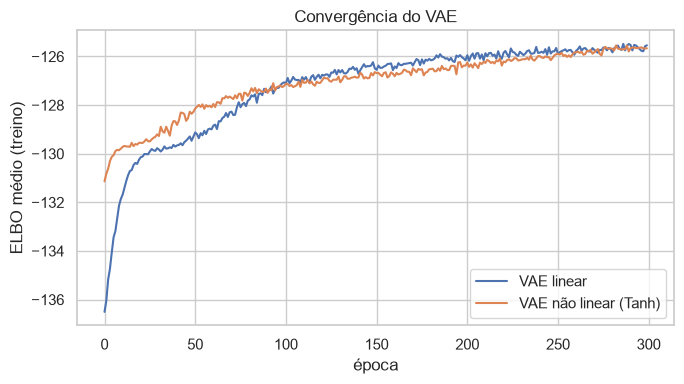

Sensibilidade a beta (VAE linear, validação cruzada):


,n_factors,n_epochs,sigma2,beta,hidden_dim,learning_rate,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,cv_nll_mean,cv_nll_std
0,20,300,2.0,1.0,None,0.01,0.9564,0.0063,0.7517,0.0041,1.5115,0.0027
1,20,300,2.0,2.0,None,0.01,0.9624,0.0076,0.7601,0.0050,1.5098,0.0035
2,20,300,2.0,0.5,None,0.01,0.9741,0.0057,0.7621,0.0041,1.5204,0.0025


Tempo de treino e inferência:


,treino (s),inferência teste (ms)
MF (SGD),37.36,53.11
PPCA (EM),38.64,5.16
VAE linear,16.34,2.29
VAE não linear,8.22,6.98


In [19]:
# Faça o treinamento e a avaliação do VAE aqui

import time


class VAEWithPadding(VAE):
    """VAE que mantém as dimensões globais do problema.

    Se algum usuário ou filme ficar fora do treino do fold, completamos as
    representações com zero. Para o decodificador, estendemos a última
    camada para que os índices globais continuem válidos.
    """

    def fit(self, train_df: pd.DataFrame) -> None:
        super().fit(train_df)

        n_users_fit = self.user_embeddings.shape[0]
        if n_users_fit < N_USERS:
            pad = N_USERS - n_users_fit
            self.user_embeddings = np.pad(
                self.user_embeddings, ((0, pad), (0, 0))
            )
            self.user_variances = np.pad(
                self.user_variances, ((0, pad), (0, 0)), constant_values=1.0
            )

        if self.hidden_dim is None:
            n_items_fit = self.decoder.out_features
        else:
            n_items_fit = self.decoder[-1].out_features

        if n_items_fit < N_ITEMS:
            pad = N_ITEMS - n_items_fit
            if self.hidden_dim is None:
                fallback = float(self.item_means.mean())
                old = self.decoder
                new = nn.Linear(self.n_factors, N_ITEMS)
                with torch.no_grad():
                    new.weight[:n_items_fit] = old.weight
                    new.bias[:n_items_fit] = old.bias
                    new.weight[n_items_fit:] = 0.0
                    new.bias[n_items_fit:] = fallback
                self.decoder = new
                self.item_embeddings = np.pad(
                    self.item_embeddings, ((0, pad), (0, 0))
                )
                self.item_means = np.pad(
                    self.item_means, (0, pad), constant_values=fallback
                )
            else:
                fallback = float(self.decoder[-1].bias.mean().item())
                new_last = nn.Linear(self.hidden_dim, N_ITEMS)
                with torch.no_grad():
                    new_last.weight[:n_items_fit] = self.decoder[-1].weight
                    new_last.bias[:n_items_fit] = self.decoder[-1].bias
                    new_last.weight[n_items_fit:] = 0.0
                    new_last.bias[n_items_fit:] = fallback
                self.decoder = nn.Sequential(
                    self.decoder[0], nn.Tanh(), new_last
                )


def make_vae(**params):
    """Cria um VAE com semente fixa, para reprodutibilidade."""
    set_seed(SEED)
    return VAEWithPadding(**params)


VAE_EPOCHS = 300
VAE_LR = 1e-2
VAE_HIDDEN = 32

# Comparação 1: decodificador linear, com o mesmo k e sigma2 do PPCA.
set_seed(SEED)
vae_linear = VAEWithPadding(
    n_factors=ppca_best_k,
    n_epochs=VAE_EPOCHS,
    sigma2=ppca_best_sigma2,
    beta=1.0,
    hidden_dim=None,
    learning_rate=VAE_LR,
)
t0 = time.perf_counter()
vae_linear.fit(train_df)
vae_linear_fit_time = time.perf_counter() - t0
vae_linear_metrics = evaluate_model(vae_linear, test=test_df)
vae_linear_preds = clip_ratings(vae_linear.predict(test_users, test_items))
vae_linear_ci = bootstrap_ci(test_ratings, vae_linear_preds, seed=SEED)

# Comparação 2: decodificador não linear com uma camada oculta e Tanh.
set_seed(SEED)
vae_nonlinear = VAEWithPadding(
    n_factors=ppca_best_k,
    n_epochs=VAE_EPOCHS,
    sigma2=ppca_best_sigma2,
    beta=1.0,
    hidden_dim=VAE_HIDDEN,
    learning_rate=VAE_LR,
)
t0 = time.perf_counter()
vae_nonlinear.fit(train_df)
vae_nonlinear_fit_time = time.perf_counter() - t0
vae_nonlinear_metrics = evaluate_model(vae_nonlinear, test=test_df)
vae_nonlinear_preds = clip_ratings(
    vae_nonlinear.predict(test_users, test_items)
)

vae_summary = pd.DataFrame(
    {
        "RMSE": [
            ppca_metrics["test_rmse"],
            vae_linear_metrics["test_rmse"],
            vae_nonlinear_metrics["test_rmse"],
        ],
        "MAE": [
            ppca_metrics["test_mae"],
            vae_linear_metrics["test_mae"],
            vae_nonlinear_metrics["test_mae"],
        ],
        "NLL": [
            ppca_metrics["test_nll"],
            vae_linear_metrics["test_nll"],
            vae_nonlinear_metrics["test_nll"],
        ],
        "RMSE IC95%": [
            f"[{ppca_ci['rmse'][0]:.4f}, {ppca_ci['rmse'][1]:.4f}]",
            f"[{vae_linear_ci['rmse'][0]:.4f}, {vae_linear_ci['rmse'][1]:.4f}]",
            "-",
        ],
    },
    index=["PPCA (EM)", "VAE linear", "VAE não linear (Tanh)"],
)

print("Comparação PPCA × VAE (teste):")
display(vae_summary.round(4))

# Curvas de convergência.
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(vae_linear.history, label="VAE linear")
ax.plot(vae_nonlinear.history, label="VAE não linear (Tanh)")
ax.set_xlabel("época")
ax.set_ylabel("ELBO médio (treino)")
ax.set_title("Convergência do VAE")
ax.legend()
fig.tight_layout()
plt.show()

# Sensibilidade: variação isolada de beta, com o protocolo de validação.
set_seed(SEED)
vae_beta_cv = cross_validate_probabilistic(
    make_vae,
    train_df,
    {
        "n_factors": [ppca_best_k],
        "n_epochs": [VAE_EPOCHS],
        "sigma2": [ppca_best_sigma2],
        "beta": [0.5, 1.0, 2.0],
        "hidden_dim": [None],
        "learning_rate": [VAE_LR],
    },
    n_folds=N_FOLDS,
    seed=SEED,
)
print("Sensibilidade a beta (VAE linear, validação cruzada):")
display(vae_beta_cv.round(4))

# Tempo de treino e de inferência.
set_seed(SEED)
mf_timed = MatrixFactorizationWithPadding(
    n_factors=mf_best_k,
    n_epochs=MF_EPOCHS,
    learning_rate=MF_LR,
    reg=mf_best_lambda_z,
    bias_reg=mf_best_lambda_b,
    use_biases=True,
)
t0 = time.perf_counter()
mf_timed.fit(train_df)
mf_fit_time = time.perf_counter() - t0


def inference_time(model) -> float:
    t0 = time.perf_counter()
    model.predict(test_users, test_items)
    return time.perf_counter() - t0


timing = pd.DataFrame(
    {
        "treino (s)": [
            mf_fit_time,
            ppca_fit_time,
            vae_linear_fit_time,
            vae_nonlinear_fit_time,
        ],
        "inferência teste (ms)": [
            1000 * inference_time(mf_timed),
            1000 * inference_time(ppca_model),
            1000 * inference_time(vae_linear),
            1000 * inference_time(vae_nonlinear),
        ],
    },
    index=["MF (SGD)", "PPCA (EM)", "VAE linear", "VAE não linear"],
)
print("Tempo de treino e inferência:")
display(timing.round(2))


**Discussão:**
*Escreva suas conclusões aqui*

---

### Visualização dos espaços latentes

Dos modelos treinados, quatro deles aprendem vetores latentes por usuário e por item: PCA com imputação, fatoração de matrizes, PPCA e VAE.
Esses vetores podem ser analisados com as mesmas ferramentas, permitindo que possamos interpretar e comparar os espaços latentes aprendidos por cada modelo.
Garante-se que pelo menos um modelo de cada tipo tenha sido treinado, e então podemos comparar os espaços latentes aprendidos.

> **Tarefa 2.3**
Visualize os espaços latentes de usuários e de itens dos quatro modelos, usando um $k$ de sua escolha, e relacione o que aparece nas figuras com informações que não foram usadas no treino: por exemplo, gênero, idade e ocupação dos usuários, e gêneros, ano e popularidade dos filmes.
>
> O espaço de cada modelo organiza essas informações, e isso pode ser medido além da inspeção visual?
Os quatro espaços compartilham a mesma estrutura, ou cada suposição produz uma geometria diferente?


**Ideias para começar.**

Para visualizar, projete os vetores em duas dimensões com PCA, que é determinístico e preserva a geometria global, e compare com o t-SNE.
Colorir os pontos por um metadado mostra se ele aparece, e um modelo supervisionado linear (`Ridge` para variáveis contínuas, `LogisticRegression` com `roc_auc_score` para categorias) pode medir quanto de informação sobre o metadado está presente no espaço latente original, sem precisar de uma projeção.

Isso permite verificar se, a partir dos vetores latentes, é possível prever a idade do usuário, o gênero do filme ou a popularidade do filme, quantificando o quanto de informação sobre essas variáveis está presente no espaço latente.

Ao comparar os espaços latentes, é importante lembrar que cada modelo aprende uma representação diferente, e que a correspondência entre os vetores latentes de um modelo e de outro não é trivial, pois os espaços latentes podem ser invariantes à rotação, reflexão e escala.
Para comparar dois espaços é necessário alinhar os vetores latentes de um modelo com os do outro, ou através de análises de correspondência de vizinhos, como a correlação de distâncias entre pontos, ou através da sobreposição dos vizinhos mais próximos de cada filme em dois modelos.

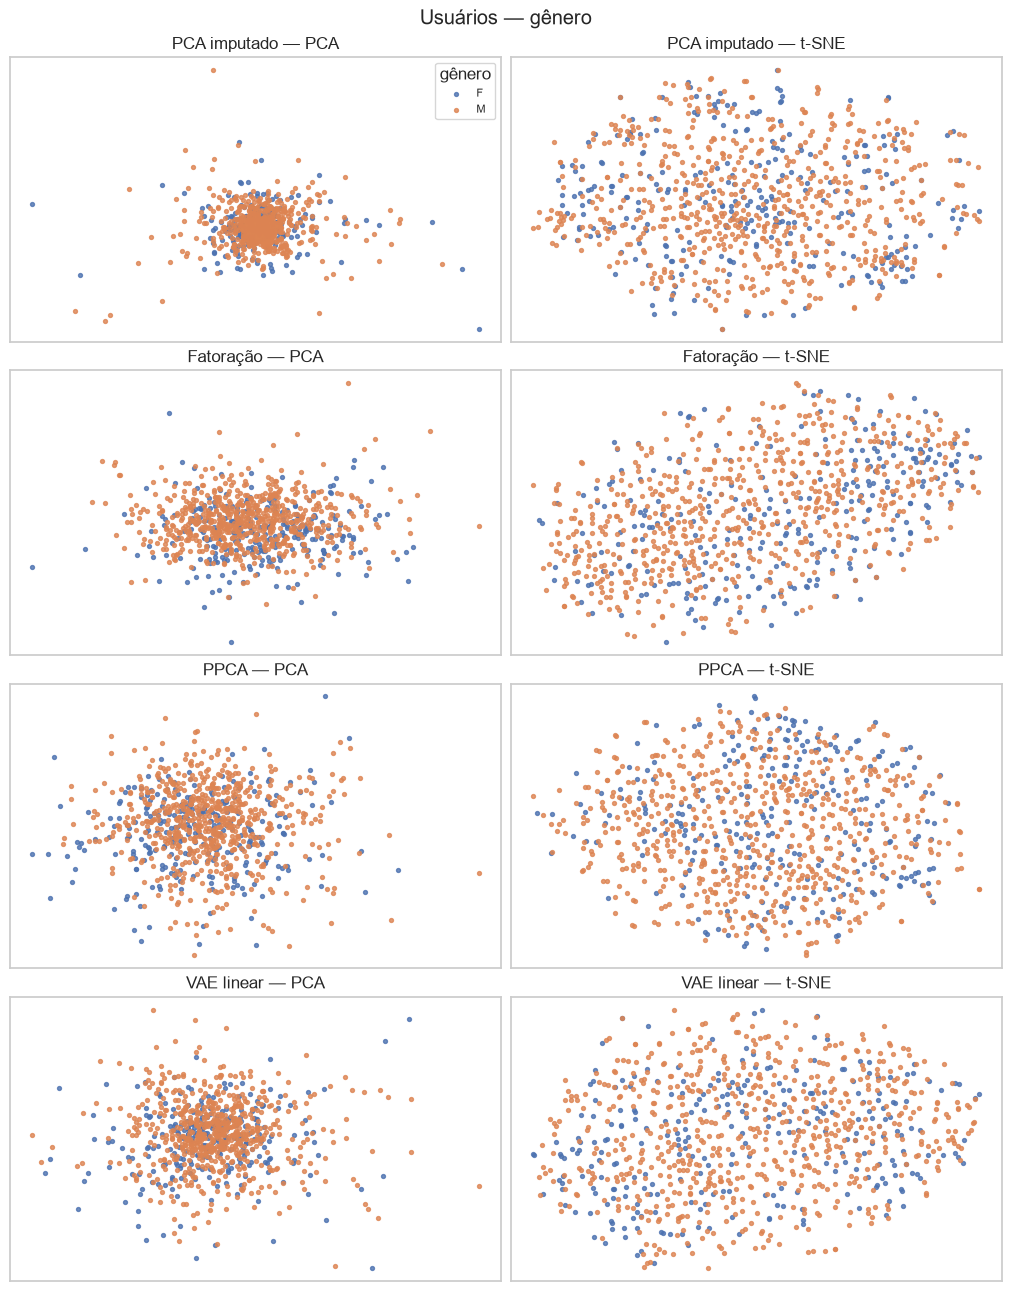

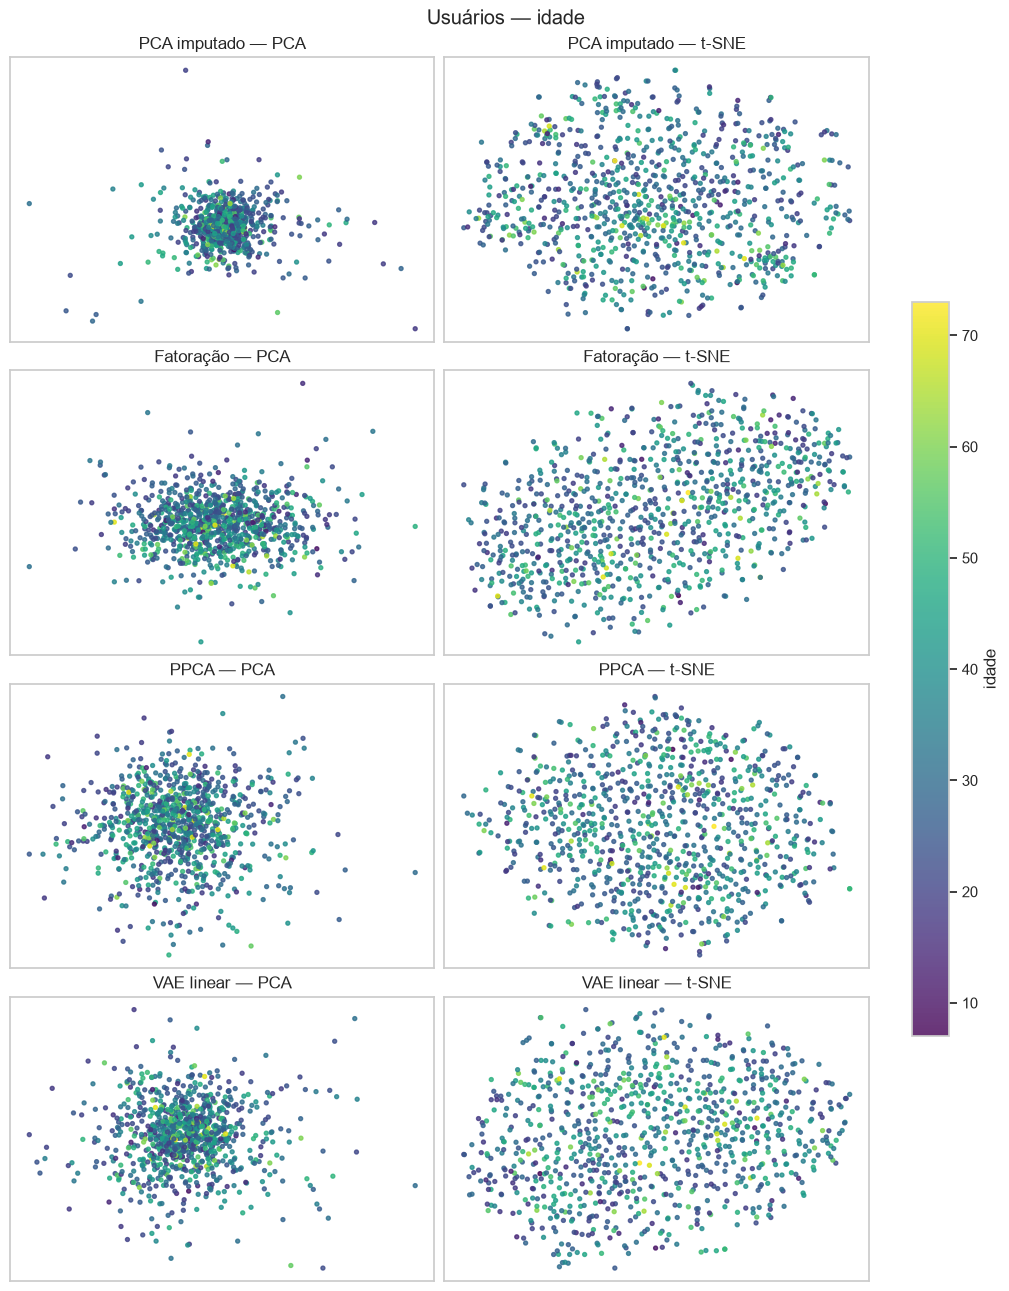

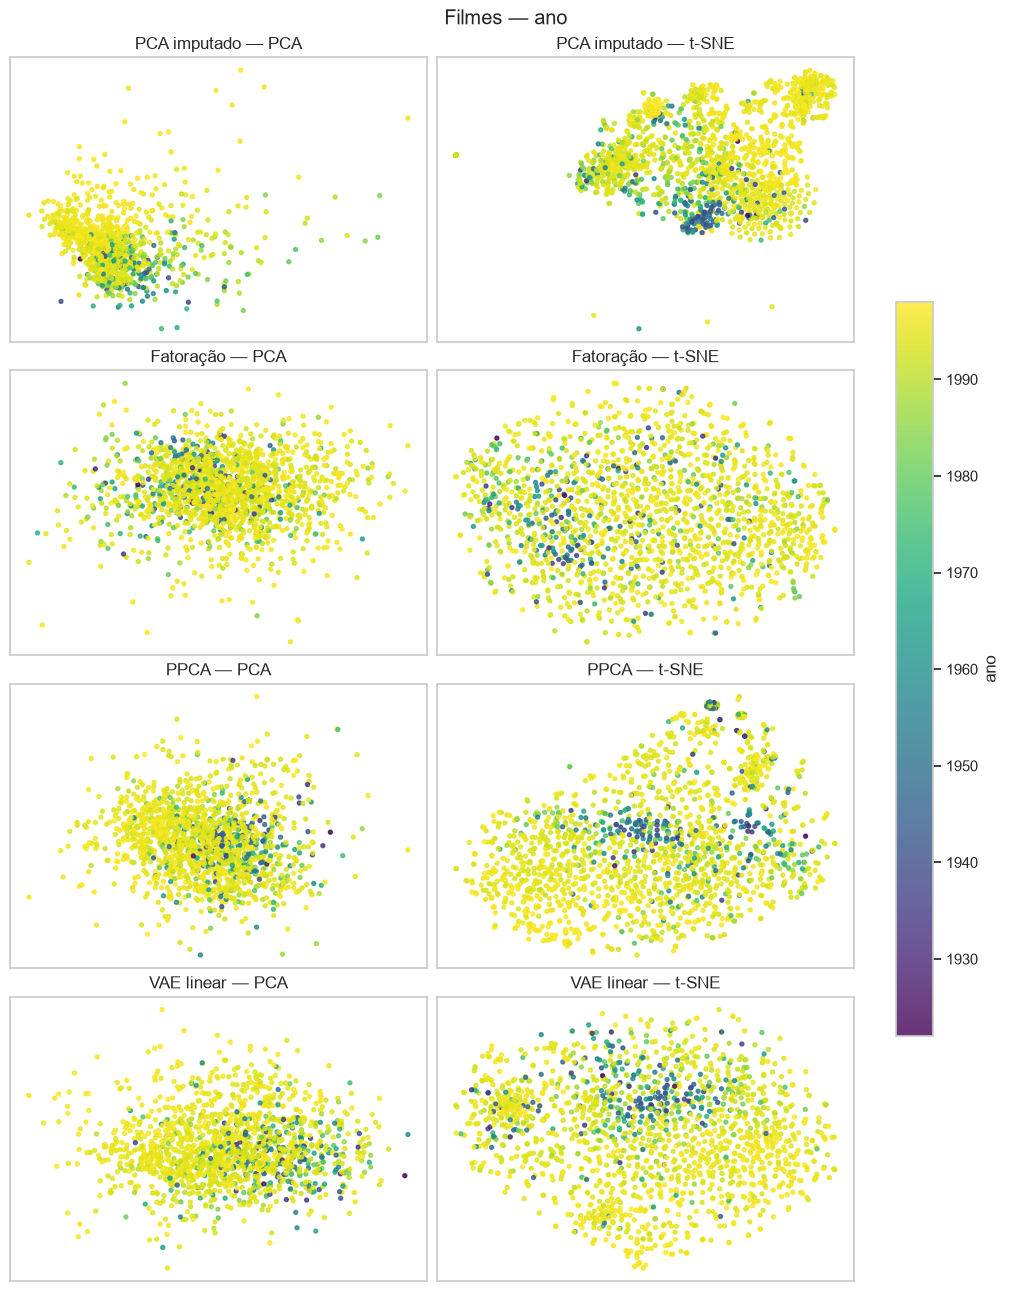

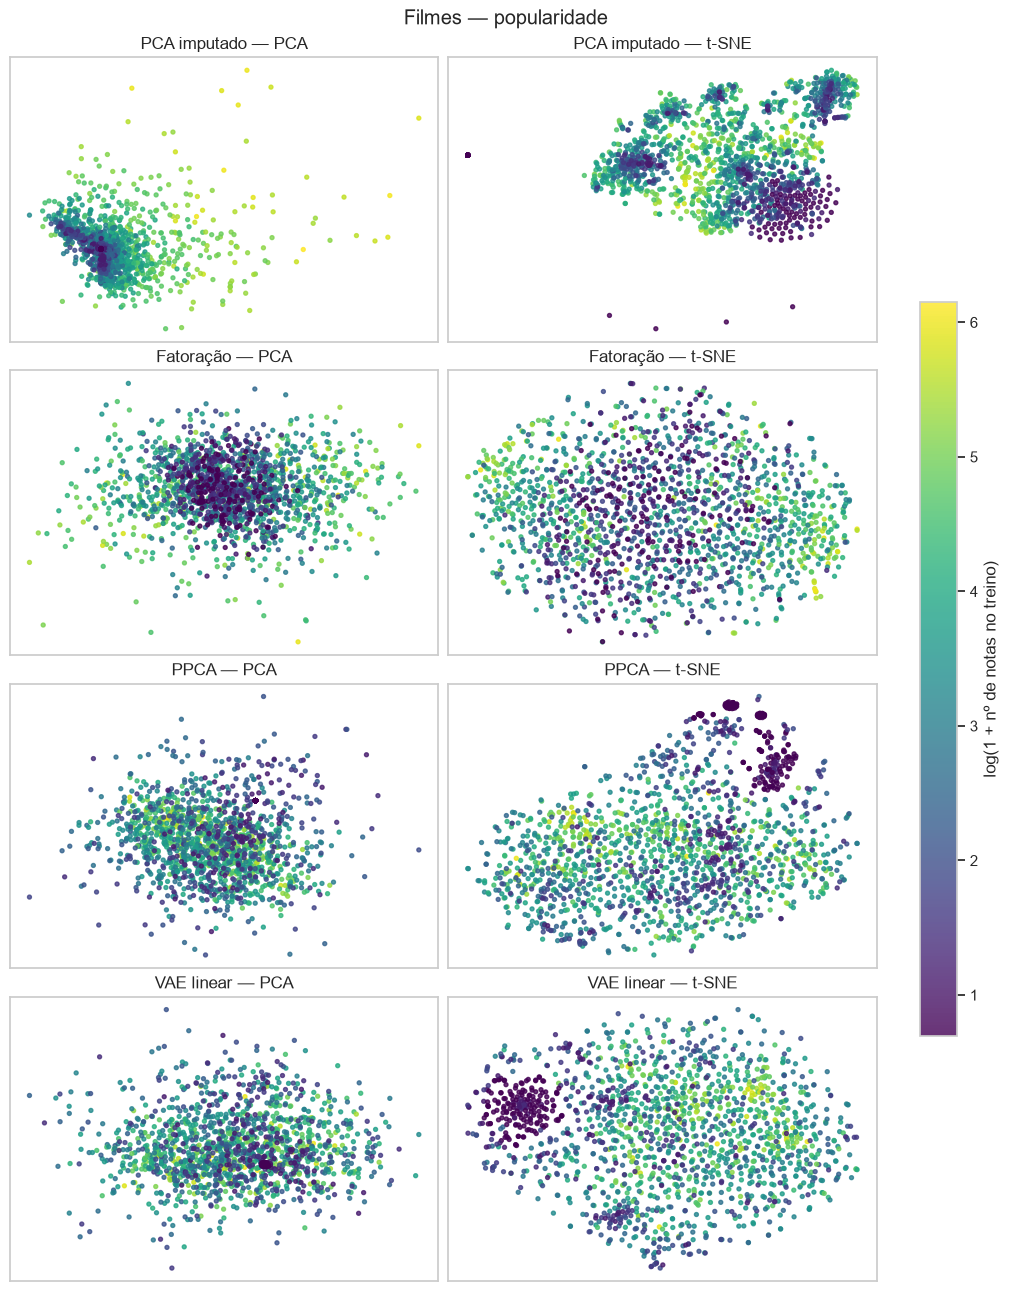

Sondagens lineares (validação cruzada de 5 folds):


,idade (R2),gênero (AUC),ocupação (AUC),ano (R2),popularidade (R2),gêneros (AUC)
PCA imputado,-0.010,0.651,0.555,0.187,0.632,0.699
Fatoração,0.035,0.647,0.519,0.052,0.010,0.651
PPCA,0.095,0.689,0.550,0.219,0.167,0.683
VAE linear,0.062,0.690,0.545,0.206,0.210,0.674


Correlação entre distâncias dos filmes:


,PCA imputado,Fatoração,PPCA,VAE linear
PCA imputado,1.000,0.369,0.063,0.024
Fatoração,0.369,1.000,0.406,0.368
PPCA,0.063,0.406,1.000,0.880
VAE linear,0.024,0.368,0.880,1.000


Sobreposição média dos 10 vizinhos mais próximos (Jaccard):


,PCA imputado,Fatoração,PPCA,VAE linear
PCA imputado,1.000,0.019,0.041,0.048
Fatoração,0.019,1.000,0.029,0.027
PPCA,0.041,0.029,1.000,0.131
VAE linear,0.048,0.027,0.131,1.000


In [20]:
# Faça as visualizações e análises dos espaços latentes aqui

from scipy.spatial.distance import pdist
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.manifold import TSNE
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

K_SPACE = ppca_best_k

# Treina PCA e fatoração no mesmo k para comparar os quatro espaços.
set_seed(SEED)
pca_space = ImputedPCAWithPadding(n_components=K_SPACE)
pca_space.fit(train_df)

set_seed(SEED)
mf_space = MatrixFactorizationWithPadding(
    n_factors=K_SPACE,
    n_epochs=MF_EPOCHS,
    learning_rate=MF_LR,
    reg=mf_best_lambda_z,
    bias_reg=mf_best_lambda_b,
    use_biases=True,
)
mf_space.fit(train_df)

spaces = {
    "PCA imputado": (pca_space.user_embeddings, pca_space.item_embeddings),
    "Fatoração": (mf_space.user_embeddings, mf_space.item_embeddings),
    "PPCA": (ppca_model.user_embeddings, ppca_model.item_embeddings),
    "VAE linear": (vae_linear.user_embeddings, vae_linear.item_embeddings),
}

user_meta = users.sort_values("user_id").reset_index(drop=True)
item_meta = movies.sort_values("item_id").reset_index(drop=True)
train_popularity = (
    train_df.groupby("item_id")
    .size()
    .reindex(np.arange(N_ITEMS), fill_value=0)
)

age = user_meta["age"].to_numpy()
gender = user_meta["gender"].to_numpy()
year = item_meta["year"].fillna(item_meta["year"].median()).to_numpy()
log_popularity = np.log1p(train_popularity.to_numpy())


def standardize(X) -> NDArray[np.float64]:
    return StandardScaler().fit_transform(np.asarray(X, dtype=np.float64))


def project_2d(X: NDArray[np.float64], method: str) -> NDArray[np.float64]:
    if method == "PCA":
        return PCA(n_components=2, random_state=SEED).fit_transform(X)
    return TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        random_state=SEED,
    ).fit_transform(X)


user_vectors = {}
item_vectors = {}
user_projections = {}
item_projections = {}

for name, (U, I) in spaces.items():
    user_vectors[name] = standardize(U)
    item_vectors[name] = standardize(I)
    user_projections[name] = {
        "PCA": project_2d(user_vectors[name], "PCA"),
        "t-SNE": project_2d(user_vectors[name], "t-SNE"),
    }
    item_projections[name] = {
        "PCA": project_2d(item_vectors[name], "PCA"),
        "t-SNE": project_2d(item_vectors[name], "t-SNE"),
    }


def plot_projection_grid(
    projections,
    colors,
    title: str,
    color_label: str,
    categorical: bool = False,
    cmap: str = "viridis",
) -> None:
    fig, axes = plt.subplots(
        len(projections), 2,
        figsize=(10, 3.2 * len(projections)),
        constrained_layout=True,
    )
    axes = np.atleast_2d(axes)

    for i, name in enumerate(projections):
        for j, method in enumerate(["PCA", "t-SNE"]):
            ax = axes[i, j]
            xy = projections[name][method]

            if categorical:
                for label in sorted(pd.unique(colors)):
                    mask = colors == label
                    ax.scatter(
                        xy[mask, 0], xy[mask, 1],
                        s=8, alpha=0.8, label=str(label),
                    )
                if i == 0 and j == 0:
                    ax.legend(title=color_label, fontsize=8)
            else:
                scatter = ax.scatter(
                    xy[:, 0], xy[:, 1],
                    c=colors, cmap=cmap, s=8, alpha=0.8,
                )

            ax.set_title(f"{name} — {method}")
            ax.set_xticks([])
            ax.set_yticks([])

    if not categorical:
        fig.colorbar(
            scatter, ax=axes.ravel().tolist(), shrink=0.6, label=color_label
        )
    fig.suptitle(title)
    plt.show()


plot_projection_grid(
    user_projections, gender, "Usuários — gênero", "gênero", categorical=True
)
plot_projection_grid(user_projections, age, "Usuários — idade", "idade")
plot_projection_grid(item_projections, year, "Filmes — ano", "ano")
plot_projection_grid(
    item_projections, log_popularity, "Filmes — popularidade",
    "log(1 + nº de notas no treino)",
)

# Sondagens lineares sobre os vetores originais.
occupation = user_meta["occupation"].copy()
occupation_counts = occupation.value_counts()
rare_occupations = occupation_counts[occupation_counts < 10].index
occupation[occupation.isin(rare_occupations)] = "other"

valid_genres = [
    genre for genre in GENRES
    if item_meta[genre].sum() >= 10
    and (len(item_meta) - item_meta[genre].sum()) >= 10
]


def cv_r2(X, y) -> float:
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    scores = cross_val_score(
        model, X, y,
        cv=KFold(5, shuffle=True, random_state=SEED),
        scoring="r2",
    )
    return float(np.mean(scores))


def cv_auc(X, y, multiclass: bool = False) -> float:
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    scoring = "roc_auc_ovr_weighted" if multiclass else "roc_auc"
    scores = cross_val_score(
        model, X, y,
        cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
        scoring=scoring,
    )
    return float(np.mean(scores))


probe_rows = {}
for name in spaces:
    U = user_vectors[name]
    I = item_vectors[name]
    probe_rows[name] = {
        "idade (R2)": cv_r2(U, age),
        "gênero (AUC)": cv_auc(U, (gender == "M").astype(int)),
        "ocupação (AUC)": cv_auc(U, occupation.to_numpy(), multiclass=True),
        "ano (R2)": cv_r2(I, year),
        "popularidade (R2)": cv_r2(I, log_popularity),
        "gêneros (AUC)": float(np.mean([
            cv_auc(I, item_meta[genre].to_numpy())
            for genre in valid_genres
        ])),
    }

probe_table = pd.DataFrame(probe_rows).T
print("Sondagens lineares (validação cruzada de 5 folds):")
display(probe_table.round(3))

# Comparação entre espaços sem alinhamento.
def distance_correlation(A, B) -> float:
    return float(np.corrcoef(pdist(A), pdist(B))[0, 1])


def jaccard_neighbors(A, B, n_neighbors: int = 10) -> float:
    def neighbors(X):
        model = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(X)
        _, indices = model.kneighbors(X)
        return [set(row[1:]) for row in indices]

    neighbors_a = neighbors(A)
    neighbors_b = neighbors(B)
    return float(np.mean([
        len(a & b) / len(a | b)
        for a, b in zip(neighbors_a, neighbors_b)
    ]))


space_names = list(item_vectors)
distance_corr = pd.DataFrame(index=space_names, columns=space_names, dtype=float)
jaccard = pd.DataFrame(index=space_names, columns=space_names, dtype=float)

for a in space_names:
    for b in space_names:
        distance_corr.loc[a, b] = distance_correlation(
            item_vectors[a], item_vectors[b]
        )
        jaccard.loc[a, b] = jaccard_neighbors(
            item_vectors[a], item_vectors[b]
        )

print("Correlação entre distâncias dos filmes:")
display(distance_corr.round(3))
print("Sobreposição média dos 10 vizinhos mais próximos (Jaccard):")
display(jaccard.round(3))


**Discussão:**
*Escreva suas conclusões aqui*

---

## Etapa 3: Projeto do grupo

Nesta última etapa, cada um de vocês deve propor um projeto de investigação, que pode ser uma melhoria do modelo ou uma análise mais profunda de algum aspecto do problema.
Após finalizar as duas primeiras etapas, verifiquem se há alguma pergunta que surgiu durante as análises e ainda não foi explorado, ou alguma hipótese que vocês gostariam de testar, por exemplo, sobre a geometria do espaço latente, uma formulação alternativa, ou um hiperparâmetro que não foi isolado.

O importante é que o projeto esteja bem definido, com uma motivação clara, uma hipótese testável e um protocolo experimental que permita avaliar o impacto da mudança proposta.

> **Tarefa 3.1**
Escolha um projeto e escreva a pergunta, a hipótese, a previsão e o experimento antes de rodar.
Defina o modelo referência, qual é a mudança proposta e qual resultado refutaria a hipótese de vocês.
Ao final, compare o que foi previsto com o que foi observado e o que o resultado diz sobre a previsão sobre o espaço latente.

**Projetos sugeridos.**
Aqui está uma lista de ideias que podem ser exploradas, mas vocês podem propor outras, desde que estejam bem justificadas.

*1. Ausência não aleatória.*
Usuários ativos e filmes populares aparecem mais nos dados, o que cria um viés de observação.
Pergunta: corrigir esse viés com pesos pelo inverso da probabilidade de observação [Schnabel et al.](https://arxiv.org/abs/1602.05352) melhora as previsões para filmes pouco avaliados, e o que acontece com os populares?

*2. Metadados como features.*
Ao invés de tratar cada usuário e item como um identificador único, podemos usar suas características como features para o "codificador".
Pergunta: usar os metadados para definir a média do prior de $\mathbf{z}$ melhora as previsões de usuários com pouco histórico?

*3. Geometria da compatibilidade.*
Todos os modelos utilizam o produto interno para medir a compatibilidade entre usuários e itens.
Pergunta: trocar o produto interno por uma distância, ou por uma pequena rede que recebe $\mathbf{z}_u$ e $\mathbf{w}_i$, muda o que o espaço codifica e o erro de previsão? Ver [Rendle et al.](https://arxiv.org/abs/2005.09683) para um resultado que motiva a pergunta.

*4. Estrutura do espaço latente.*
A selecão de hiperparâmetros não observou a geometria do espaço latente, mas apenas o erro de previsão.
Pergunta: o que muda no espaço latente aprendido do VAE ao variar $\beta$, o tamanho do espaço ou a regularização, em termos de estabilidade de clusters, correlação com metadados e erro de previsão?

In [21]:
# Desenvolva o experimento do seu grupo aqui

**Discussão:**
*Escreva suas conclusões aqui*